In [1]:
import pandas as pd
import numpy as np
#from lm_polygraph.generation_metrics import AlignScore

In [2]:
def calc_lengths(dat, tokenizer):
    def tokenize(question, context, answer):
        answer = str(answer)
        messages = [
            {"role": "user", "content": f"Question:\n{question}\nContext:\n{context}\n"},
            {"role": "assistant", "content": f"Answer:\n{answer}\n"},
        ]
        text = tokenizer.apply_chat_template(
            messages,
            tokenize=True,
            add_generation_prompt=False
        )
        return len(text)
    lengths = []
    for idx in range(len(dat)):
        toks = tokenize(dat["question"].loc[idx], dat["context"].loc[idx], dat["target"].loc[idx])
        lengths.append(toks)
    return lengths    

In [3]:
from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained("google/gemma-3-1b-it")

/home/jovyan/gkuzmin/llm_ue/conda_llm_ue_env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
def calc_em_cuad(targets, preds, is_mamba=False, is_filtered=False):
    exact_match = []
    for target, pred in zip(targets, preds):
        try:
            parsed_pred = pred.split("Answer:\n")[1]
            parsed_pred = parsed_pred.split("\n")[0]
        except:
            parsed_pred = pred
        if is_mamba:
            try:
                parsed_pred = pred.split("Answer:\n")[1]
                parsed_pred = parsed_pred.split("<|")[0]
            except:
                parsed_pred = pred
        if is_filtered:
            parsed_pred = pred
        exact_match.append(int(str(target).strip() == str(parsed_pred).strip()))
    return exact_match

In [5]:
def calc_alignscore(targets, preds, scorer):
    filtered_preds = []
    for pred in preds:
        try:
            parsed_pred = pred.split("Answer:\n")[1]
            parsed_pred = parsed_pred.split("\n")[0]
        except:
            parsed_pred = pred
        filtered_preds.append(str(parsed_pred))
    scores = scorer({"greedy_texts": filtered_preds}, [str(el) for el in targets])
    return scores

## Now load results after merge

In [6]:
# load and process additional res
add_fnames = [
    
    # gemma after mask fix
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/base_model/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/google/gemma-3-1b-it/mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-05_10000/checkpoint-10000/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    # gemma3-1b left pad assist mask es 15 no sw
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_4k/google/gemma-3-1b-it/mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x1024_4032_64_1e-05_10000/checkpoint-8400/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/google/gemma-3-1b-it/mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_10000/checkpoint-200/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/google/gemma-3-1b-it/no_cl_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_10000/checkpoint-9900/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/base_model/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/google/gemma-3-1b-it/mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-05_50000/checkpoint-9800/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    # gemma3-1b left pad assist mask es 15 no sw, from 2s
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_4k/google/gemma-3-1b-it/from_2s_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x1024_4032_64_1e-05_10000/checkpoint-9000/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/google/gemma-3-1b-it/from_2s_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_10000/checkpoint-200/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/google/gemma-3-1b-it/no_cl_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_50000/checkpoint-9900/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    #bigger lora
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/base_model/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/google/gemma-3-1b-it/mask_fix_assist_mask_es15_all_lin_128_256_SEGM_1x8192_8192_64_1e-05_10000/checkpoint-9900/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    # prelim armt with bigger lora
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_4k/google/gemma-3-1b-it/mask_fix_assist_mask_es15_all_lin_128_256_sink_SEGM_4x1024_4032_64_1e-05_10000/checkpoint-8400/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_2k/google/gemma-3-1b-it/mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_2016_64_1e-05_10000/checkpoint-9700/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_2k/google/gemma-3-1b-it/from_2s_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_2016_64_1e-05_10000/checkpoint-6400/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_2k/google/gemma-3-1b-it/mask_fix_assist_mask_es15_all_lin_128_256_sink_SEGM_2x1024_2016_64_1e-05_10000/checkpoint-7800/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_2k/google/gemma-3-1b-it/mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_1984_64_1e-05_10000/checkpoint-9900/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/google/gemma-3-1b-it/no_cl_mask_fix_assist_mask_es15_all_lin_128_256_sink_SEGM_8x1024_8064_64_1e-05_10000/checkpoint-9900/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_2k/google/gemma-3-1b-it/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_2016_64_1e-04_10000/checkpoint-4300/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",


    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_2k/google/gemma-3-1b-it/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_2016_64_1e-04_10000/checkpoint-7000/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_2k/google/gemma-3-1b-it/bl_pars_mem_32_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_1984_64_1e-04_10000/checkpoint-7100/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_2k/google/gemma-3-1b-it/bl_pars_group_len_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_2016_64_1e-04_10000/checkpoint-6700/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_4k/google/gemma-3-1b-it/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x1024_4032_64_1e-04_10000/checkpoint-500/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/google/gemma-3-1b-it/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-04_10000/checkpoint-200/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_4k/google/gemma-3-1b-it/lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x1024_4032_64_3e-05_10000/checkpoint-4000/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-04_10000/checkpoint-200/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_3e-05_10000/checkpoint-4400/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_3e-05_10000/checkpoint-4700/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_10000/checkpoint-5100/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/base_model/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-04_10000/checkpoint-4000/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/base_model/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-04_10000/checkpoint-9700/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    # cl-rev
    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_256/google/gemma-3-1b-it/cl_rev_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x128_224_64_1e-04_1000/checkpoint-430/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_512/google/gemma-3-1b-it/cl_rev_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x128_448_64_5e-05_4000/checkpoint-880/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_1k/google/gemma-3-1b-it/cl_rev_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x256_960_64_3e-05_6000/checkpoint-1980/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_2k/google/gemma-3-1b-it/cl_rev_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x512_1984_64_2e-05_10000/checkpoint-3500/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_4k/google/gemma-3-1b-it/cl_rev_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x1024_4032_64_1e-05_10000/checkpoint-3500/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    # cl-rev on script-version of data
    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2_script_version/manytypes_flat_stacked_no_empty_sv_0k_0.25k_val_0.25k/google/gemma-3-1b-it/new_data_cl_rev_v2_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x128_224_64_1e-4_10000/checkpoint-1500/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2_script_version/manytypes_flat_stacked_no_empty_sv_0k_0.5k_val_0.5k/google/gemma-3-1b-it/new_data_cl_rev_v2_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x128_448_64_1e-4_10000/checkpoint-3300/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2_script_version/manytypes_flat_stacked_no_empty_sv_0k_1k_val_1k/google/gemma-3-1b-it/new_data_cl_rev_v2_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x256_960_64_1e-4_10000/checkpoint-3400/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2_script_version/manytypes_flat_stacked_no_empty_sv_0k_2k_val_2k/google/gemma-3-1b-it/new_data_cl_rev_v2_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x512_1984_64_1e-4_10000/checkpoint-400/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2_script_version/manytypes_flat_stacked_no_empty_sv_0k_4k_val_4k/google/gemma-3-1b-it/new_data_cl_rev_v2_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x1024_4032_64_3e-5_10000/checkpoint-3100/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/qa_test_pre_quest_yes__qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_3e-05_10000/checkpoint-4700/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_0;1;2;3;4;5;6.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_3e-05_10000/checkpoint-4700/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_7;8;9;10;11;12.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_3e-05_10000/checkpoint-4700/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_13;14;15;16;17;18.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_3e-05_10000/checkpoint-4700/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_19;20;21;22;23;24;25.csv",
    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_10000/checkpoint-5100/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_0;1;2;3;4;5;6.csv",
    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_10000/checkpoint-5100/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_7;8;9;10;11;12.csv",
    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_10000/checkpoint-5100/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_13;14;15;16;17;18.csv",
    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_10000/checkpoint-5100/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_19;20;21;22;23;24;25.csv",

    
]

#abl_fname = [f"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_10000/checkpoint-5100/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_{idx}.csv" for idx in range(26)]
abl_fname = [f"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_3e-05_10000/checkpoint-4700/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_{idx}.csv" for idx in range(26)]

add_fnames+=abl_fname
add_fnames += [
    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_10000/checkpoint-5100/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_0;1;2;3;4;5;6;7;8;9;10;11;12.csv",
    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_10000/checkpoint-5100/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_13;14;15;16;17;18;19;20;21;22;23;24;25.csv",
    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_10000/checkpoint-5100/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_0;1;2;3;4;5;6;7;8;9;10;11;12;13;15;16;17;18;19;20;21;22;23;24;25.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_3e-05_10000/checkpoint-4700/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_0;1;2;3;4;5;6;7;8;9;10;11;12.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_3e-05_10000/checkpoint-4700/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_13;14;15;16;17;18;19;20;21;22;23;24;25.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_3e-05_10000/checkpoint-4700/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_0;1;2;3;4;5;6;7;8;9;10;11;12;13;15;16;17;18;19;20;21;22;23;24;25.csv",
    
    
    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_10000/checkpoint-5100/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_0;1;2;3;4;5;6;7;9;10;11;12;15;16;17;19;20;21;22;23;24;25.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_3e-05_10000/checkpoint-4700/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_0;1;2;3;4;5;6;7;8;9;10;11;12;13;15;16;17;20;21;22;23;24.csv",


    # after workshop paper
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_2k/google/gemma-3-1b-it/top_4_assoc_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_2016_64_1e-04_10000/checkpoint-7000/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_4k/google/gemma-3-1b-it/top_4_assoc_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x1024_4032_64_1e-04_10000/checkpoint-4400/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2_script_version/manytypes_flat_stacked_no_empty_sv_0k_2k_val_2k/google/gemma-3-1b-it/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_2016_64_1e-04_10000/checkpoint-9900/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2_script_version/manytypes_flat_stacked_no_empty_sv_0k_4k_val_4k/google/gemma-3-1b-it/lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x1024_4032_64_3e-05_10000/checkpoint-2000/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2_script_version/manytypes_flat_stacked_no_empty_sv_0k_8k_val_8k/google/gemma-3-1b-it/recalc_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_10000/checkpoint-4400/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/top_4_assoc_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_3e-05_10000/checkpoint-2400/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/top_4_assoc_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_3e-05_10000/checkpoint-4200/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_2k/google/gemma-3-1b-it/top_N_assoc_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_2016_64_1e-04_10000/checkpoint-7100/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_4k/google/gemma-3-1b-it/top_N_assoc_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x1024_4032_64_1e-04_10000/checkpoint-4500/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/top_N_assoc_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_3e-05_10000/checkpoint-5100/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/mamba_res/qa_evals_mt_0k_64k_600_v2-base/AntonV/mamba2-1.3b-hf/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_no_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/mamba_res/qa_evals_mt_0k_64k_600_v2-mnt16/AntonV/mamba2-1.3b-hf/home/bulatov/rmt/llm-rmt/armt-instruct-tune/runs/finetune/base_model/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/AntonV/mamba2-1.3b-hf/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x4096_4096_64_1e-04_10000/checkpoint-6600/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/mamba_res/qa_evals_mt_0k_64k_600_v2-mnt64/AntonV/mamba2-1.3b-hf/home/bulatov/rmt/llm-rmt/armt-instruct-tune/runs/finetune/base_model/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/AntonV/mamba2-1.3b-hf/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x4096_4096_64_1e-04_10000/checkpoint-6600/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    # smollm results
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_2k/HuggingFaceTB/SmolLM2-360M-Instruct/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_2016_64_1e-04_10000/checkpoint-6200/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_4k/HuggingFaceTB/SmolLM2-360M-Instruct/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x1024_4032_64_1e-04_10000/checkpoint-4200/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/HuggingFaceTB/SmolLM2-360M-Instruct/lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_3e-05_10000/checkpoint-4700/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_2k/HuggingFaceTB/SmolLM2-360M-Instruct/top_N_assoc_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_2016_64_1e-04_10000/checkpoint-7100/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_4k/HuggingFaceTB/SmolLM2-360M-Instruct/top_N_assoc_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x1024_4032_64_1e-04_10000/checkpoint-4400/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/HuggingFaceTB/SmolLM2-360M-Instruct/top_N_assoc_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_3e-05_10000/checkpoint-3900/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/qa_test_pre_quest_yes__qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/runs/finetune/base_model/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/HuggingFaceTB/SmolLM2-360M-Instruct/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-04_10000/checkpoint-3600/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    
    # pretrain results
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_2k/google/gemma-3-1b-it/from_new_pretrain_old_impl_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_1984_64_1e-04_10000/checkpoint-7100/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_4k/google/gemma-3-1b-it/from_new_pretrain_old_impl_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x1024_3968_64_1e-04_10000/checkpoint-200/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/google/gemma-3-1b-it/from_new_pretrain_old_impl_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_7936_64_3e-05_10000/checkpoint-700/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    # block ablations
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/HuggingFaceTB/SmolLM2-360M-Instruct/lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_3e-05_10000/checkpoint-4700/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_0;1;2;3;4;5;6;7.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/HuggingFaceTB/SmolLM2-360M-Instruct/lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_3e-05_10000/checkpoint-4700/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_8;9;10;11;12;13;14;15.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/HuggingFaceTB/SmolLM2-360M-Instruct/lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_3e-05_10000/checkpoint-4700/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_16;17;18;19;20;21;22;23.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/HuggingFaceTB/SmolLM2-360M-Instruct/lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_3e-05_10000/checkpoint-4700/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_24;25;26;27;28;29;30;31.csv",

]


abl_fname = [f"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/HuggingFaceTB/SmolLM2-360M-Instruct/lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_3e-05_10000/checkpoint-4700/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_{idx}.csv" for idx in range(32)]

add_fnames+=abl_fname

add_fnames += [
    # top-4 layers
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/HuggingFaceTB/SmolLM2-360M-Instruct/lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_3e-05_10000/checkpoint-4700/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_0;1;2;3;4;5;6;7;8;9;10;11;12;13;15;16;18;19;20;21;22;25;26;27;28;29;30;31.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/google/gemma-3-1b-it/from_new_pretrain_old_impl_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_7936_64_3e-05_10000/checkpoint-1600/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/google/gemma-3-1b-it/from_new_pretrain_old_impl_no_cl_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_7936_64_1e-04_10000/checkpoint-800/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/HuggingFaceTB/SmolLM2-360M-Instruct/lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_3e-05_10000/checkpoint-4700/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_0;1;2;3;4;5;6;7;8;9;10;11;12;13;14;15;16;17;18;19;20;21;22;24;25;26;27;28;29;30;31.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/google/gemma-3-1b-it/from_new_pretrain_old_impl_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_7936_64_3e-05_10000/checkpoint-2000/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/google/gemma-3-1b-it/from_new_pretrain_old_impl_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_7936_64_3e-05_10000/checkpoint-3000/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    # new res after ARR - final trained ARMT from pre-train
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/google/gemma-3-1b-it/from_new_pretrain_old_impl_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_7936_64_3e-05_10000/checkpoint-5100/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/google/gemma-3-1b-it/from_new_pretrain_old_impl_no_cl_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_7936_64_1e-04_10000/checkpoint-9700/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    # mem 32
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_2k/google/gemma-3-1b-it/mem_32_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_1984_64_1e-04_10000/checkpoint-6500/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_4k/google/gemma-3-1b-it/mem_32_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x1024_3968_64_1e-04_10000/checkpoint-400/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/google/gemma-3-1b-it/mem_32_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_7936_64_3e-05_10000/checkpoint-4700/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

]



abl_fname = [f"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/google/gemma-3-1b-it/from_new_pretrain_old_impl_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_7936_64_3e-05_10000/checkpoint-5100/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_{idx}.csv" for idx in range(26)]

add_fnames+=abl_fname

abl_fname = [f"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/google/gemma-3-1b-it/mem_32_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_7936_64_3e-05_10000/checkpoint-4700/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_{idx}.csv" for idx in range(26)]

add_fnames+=abl_fname


add_fnames += [
    # xlstm_res
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/xlstm_res_new/xlstm-evals-fixed/qa_evals_mt_0k_64k_600_v2_xlstm_stage1/NX-AI/xlstm_scaling_laws/workspace-SR006.nfs2/bulatov/rmt/llm-armt/runs/finetune/xlstm/AIRI-NLP/manytypes_v2_flat_stacked_no_empty_sv_0k_2k/NX-AI/xlstm_scaling_laws/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_ctx_1984_1e-4_10000/run_37/checkpoint-3300/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/xlstm_res_new/xlstm-evals-fixed/qa_evals_mt_0k_64k_600_v2_xlstm_stage2/NX-AI/xlstm_scaling_laws/workspace-SR006.nfs2/bulatov/rmt/llm-armt/runs/finetune/xlstm/AIRI-NLP/manytypes_v2_flat_stacked_no_empty_sv_0k_4k/NX-AI/xlstm_scaling_laws/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_ctx_3968_1e-4_10000/run_37/checkpoint-4000/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/xlstm_res_new/xlstm-evals-fixed/qa_evals_mt_0k_64k_600_v2_xlstm_stage3/NX-AI/xlstm_scaling_laws/workspace-SR006.nfs2/bulatov/rmt/llm-armt/runs/finetune/xlstm/AIRI-NLP/manytypes_v2_flat_stacked_no_empty_sv_0k_8k_val_16k/NX-AI/xlstm_scaling_laws/lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_ctx_7936_3e-5_10000/run_37/checkpoint-900/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    # top-5 pre-selected with pretrained
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_2k/google/gemma-3-1b-it/fixed_from_new_pretrain_top_N_universal_old_impl_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_1984_64_1e-04_10000/checkpoint-7000/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_4k/google/gemma-3-1b-it/fixed_from_new_pretrain_top_N_universal_old_impl_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x1024_3968_64_1e-04_10000/checkpoint-300/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    # yarn
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/runs/finetune/base_model/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/home/jovyan/gkuzmin/rmt_it/runs/finetune/base_model/pg19_subset_yarn_full/HuggingFaceTB/SmolLM2-360M-Instruct/full_pg19_yarn_16_sub_train_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x32768_32768_64_1e-04_400/checkpoint-400/from_full_pg19_adapt_yarn_16_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-04_10000/checkpoint-300/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/google/gemma-3-1b-it/fixed_from_new_pretrain_top_N_universal_old_impl_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_7936_64_3e-05_10000/checkpoint-4900/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/google/gemma-3-1b-it/no_cl_fixed_from_new_pretrain_top_N_universal_old_impl_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_7936_64_1e-04_10000/checkpoint-7900/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/runs/finetune/base_model/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/HuggingFaceTB/SmolLM2-360M-Instruct/yarn_hf_4_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-04_10000/checkpoint-1100/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/runs/finetune/base_model/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k//home/jovyan/gkuzmin/rmt_it/runs/finetune/base_model/pg19_subset_yarn_full/HuggingFaceTB/SmolLM2-360M-Instruct/full_pg19_yarn_hf_4_sub_train_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x32768_32768_64_1e-04_400/checkpoint-400/from_full_pg19_adapt_yarn_hf_4_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-04_10000/checkpoint-300/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

]


add_mod_names = [


    "Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15-mask-shift",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift",

    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-no-cl-assist-mask-left-pad-es15_no_sw-mask-shift",

    "Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15-mask-shift-50k",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift (from 2s inst)",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift (from 2s inst)",

    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-no-cl-assist-mask-left-pad-es15_no_sw-mask-shift-50k",

    "Gemma3-1b-IT-all-lin-128-256-MT-8s-assist-mask-left-pad-es15-mask-shift",
    "ARMT-Gemma3-1b-IT-all-lin-128-256-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift",

    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift (from 2s inst)",
    "ARMT-Gemma3-1b-IT-all-lin-128-256-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-mem-32-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift",

    "ARMT-Gemma3-1b-IT-all-lin-128-256-MT-8s-no-cl-assist-mask-left-pad-es15_no_sw-mask-shift",

    #"ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-1e4-bs64",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-1e4-bs64-7000",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-1e4-bs64-mem-16",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-with-group-1e4-bs64",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-1e4-bs64",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-1e4-bs64",

    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-3e5-bs64-low-lr",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-1e4-bs64-long-val",
    #"ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-3e5-bs64-long-val-from-high-lr",

    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-3e5-bs64-long-val-from-high-lr-final",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-3e5-bs64-long-val-from-low-lr",

    #"Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15-mask-shift-no-group-1e4-bs64",
    "Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15-mask-shift-no-group-1e4-bs64-9700",

    #"ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-128-256-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-1e4-bs64",
    #"ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-128-512-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-1e4-bs64",
    #"ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-256-1k-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-1e4-bs64",
    #"ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-512-2k-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-1e4-bs64",
    #"ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-1024-4k-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-1e4-bs64",

    #"ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-128-256-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-1e4-bs64_script",
    #"ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-128-512-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-1e4-bs64_script",
    #"ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-256-1k-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-1e4-bs64_script",
    #"ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-512-2k-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-1e4-bs64_script",
    #"ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-1024-4k-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-1e4-bs64_script",

    "Gemma3-1b-IT-base-prompt",
    "Gemma3-1b-IT-inst-prompt",

    #"ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-3e5-bs64-long-val-from-low-lr-0-6",
    #"ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-3e5-bs64-long-val-from-low-lr-7-12",
    #"ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-3e5-bs64-long-val-from-low-lr-13-18",
    #"ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-3e5-bs64-long-val-from-low-lr-19-25",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-3e5-bs64-long-val-from-high-lr-final-0-6",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-3e5-bs64-long-val-from-high-lr-final-7-12",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-3e5-bs64-long-val-from-high-lr-final-13-18",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-3e5-bs64-long-val-from-high-lr-final-19-25",
]

#abl_names = [f"ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-3e5-bs64-long-val-from-low-lr-{idx}" for idx in range(26)]
abl_names = [f"ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-3e5-bs64-long-val-from-high-lr-final-{idx}" for idx in range(26)]

add_mod_names+= abl_names
add_mod_names += [
    #"ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-3e5-bs64-long-val-from-low-lr-0-12",
    #"ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-3e5-bs64-long-val-from-low-lr-13-26",
    #"ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-3e5-bs64-long-val-from-low-lr-only-14-left",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-3e5-bs64-long-val-from-high-lr-final-0-12",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-3e5-bs64-long-val-from-high-lr-final-13-26",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-3e5-bs64-long-val-from-high-lr-final-only-14-left",
    
    #"ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-3e5-bs64-long-val-from-low-lr-top-4-left",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-3e5-bs64-long-val-from-high-lr-final-top-4-left",

    # new results
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-top-4-trained",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-top-4-trained",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-script-version-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-script-version-4s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-script-version-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-top-4-trained",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-top-4-trained-final",

    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-top-5-trained",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-top-5-trained",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-top-5-trained",

    "Mamba-base",
    "Mamba-train-16",
    "Mamba-train-64",

    "ARMT-SmolLM2-360M-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group",
    "ARMT-SmolLM2-360M-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group",
    "ARMT-SmolLM2-360M-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group",
    "ARMT-SmolLM2-360M-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-top-6-trained",
    "ARMT-SmolLM2-360M-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-top-6-trained",
    "ARMT-SmolLM2-360M-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-top-6-trained",

    "SmolLM2-360M-IT-base-prompt",
    "SmolLM2-360M-IT-inst-prompt",
    "SmolLM2-360M-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15-mask-shift-no-group",

    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-from-pretrained",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-from-pretrained",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-from-pretrained=prelim",

    "ARMT-SmolLM2-360M-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-final-0-7",
    "ARMT-SmolLM2-360M-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-final-8-15",
    "ARMT-SmolLM2-360M-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-final-16-23",
    "ARMT-SmolLM2-360M-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-final-24-31",

]

abl_names = [f"ARMT-SmolLM2-360M-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-{idx}" for idx in range(32)]

add_mod_names+= abl_names

add_mod_names += [
    
    "ARMT-SmolLM2-360M-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-final-top-4-layers",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-from-pretrained-prelim-2",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-from-pretrained-no-cl",
    "ARMT-SmolLM2-360M-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-final-top-1-layer",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-from-pretrained-prelim-3",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-from-pretrained-prelim-4",

    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-from-pretrained-final",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-from-pretrained-no-cl-final",

    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-mem-32",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-mem-32",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-mem-32",
    
]

abl_names = [f"ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-from-pretrained-final-{idx}" for idx in range(26)]

add_mod_names+= abl_names

abl_names = [f"ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-mem-32-{idx}" for idx in range(26)]

add_mod_names+= abl_names


add_mod_names += [
    "XLSTM-stage1",
    "XLSTM-stage2",
    "XLSTM-stage3",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-from-pretrained-top-5-trained",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-from-pretrained-top-5-trained",
    "SmolLM2-360M-IT-yarn-with-adapt",

    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-from-pretrained-top-5-trained",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-from-pretrained-top-5-trained-no-cl",
    "SmolLM2-360M-IT-yarn-hf",
    "SmolLM2-360M-IT-yarn-hf-with-adapt",

    
]

add_fnames = add_fnames[:]
add_mod_names = add_mod_names[:]
add_new_index = add_mod_names


In [8]:
for idx in [83,84,128, 129]:
    print(add_fnames[idx])

/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_2k/google/gemma-3-1b-it/from_new_pretrain_old_impl_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_1984_64_1e-04_10000/checkpoint-7100/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv
/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_4k/google/gemma-3-1b-it/from_new_pretrain_old_impl_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x1024_3968_64_1e-04_10000/checkpoint-200/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv
/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manyt

In [9]:
dat = pd.read_csv(add_fnames[0])
for idx, fname in enumerate(add_fnames[1:]):
    buf_dat = pd.read_csv(fname)
    #dat[f"output_{idx}"] = buf_dat["output"]
    dat[add_mod_names[idx+1]] = buf_dat["output"]
dat = dat.rename({"output": add_mod_names[0]}, axis=1)

/tmp/ipykernel_662538/2343262370.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dat[add_mod_names[idx+1]] = buf_dat["output"]
/tmp/ipykernel_662538/2343262370.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dat[add_mod_names[idx+1]] = buf_dat["output"]
/tmp/ipykernel_662538/2343262370.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-frag

In [10]:
len(add_fnames), len(add_mod_names)

(195, 195)

In [11]:
# map results for xlstm models

In [12]:
add_fnames[187]

'/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_64k_600_v2_bal_sup/xlstm_res_new/xlstm-evals-fixed/qa_evals_mt_0k_64k_600_v2_xlstm_stage3/NX-AI/xlstm_scaling_laws/workspace-SR006.nfs2/bulatov/rmt/llm-armt/runs/finetune/xlstm/AIRI-NLP/manytypes_v2_flat_stacked_no_empty_sv_0k_8k_val_16k/NX-AI/xlstm_scaling_laws/lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_ctx_7936_3e-5_10000/run_37/checkpoint-900/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv'

In [13]:
xlstm_res = pd.read_csv(add_fnames[187])
base_res = pd.read_csv(add_fnames[0])

In [14]:
base_res["question"] == xlstm_res["question"][0]

0        True
1       False
2       False
3       False
4       False
        ...  
1295    False
1296    False
1297    False
1298    False
1299    False
Name: question, Length: 1300, dtype: bool

In [15]:
xlstm_res

,Unnamed: 0,target,output,question,context,time
0,0,typing.Any,Answer:\ntyping.Any,What is the type of variable sociallogin?,"from typing import Tuple , Union \nimport typi...",4.858754
1,1,builtins.bool,Answer:\nbuiltins.bool,What is the type of variable resets_positions?,"from typing import Any , Dict \nimport typing ...",2.365760
2,2,builtins.float,Answer:\ntyping.Any,What is the type of variable max_ram?,"from typing import Any , Dict , List \nimport ...",1.546053
3,3,builtins.str,Answer:\nbuiltins.str,What is the type of variable DATABASES_KEY?,[comment] \n[comment] \n[comment] \n[comment] ...,0.200647
4,4,typing.Any,Answer:\ntyping.Any,What is the type of variable total_expected_ra...,"from typing import Type , Any \nimport backend...",2.211833
...,...,...,...,...,...,...
1295,1295,typing.List[builtins.str],Answer:\nbuiltins.str,What is the type of variable NESTED_AT_RULE?,from typing import Any \nimport typing \nimpor...,0.761198
1296,1296,builtins.float,Answer:\nbuiltins.int,What is the type of variable MIN_PASS_DIST?,from typing import Any \nimport typing \nimpor...,0.849360
1297,1297,NaN,Answer:\nbuiltins.str,What is the type of variable add_realm_args?,"from typing import List , Tuple \nimport djang...",0.833782
1298,1298,NaN,Answer:\ndjango.http.HttpResponse,What is the type of variable queue_json_publish?,"from typing import List , Tuple \nimport djang...",0.865586


In [16]:
dat

,Unnamed: 0,target,Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15-mask-shift,question,context,time,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-no-cl-assist-mask-left-pad-es15_no_sw-mask-shift,Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15-mask-shift-50k,...,XLSTM-stage1,XLSTM-stage2,XLSTM-stage3,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-from-pretrained-top-5-trained,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-from-pretrained-top-5-trained,SmolLM2-360M-IT-yarn-with-adapt,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-from-pretrained-top-5-trained,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-from-pretrained-top-5-trained-no-cl,SmolLM2-360M-IT-yarn-hf,SmolLM2-360M-IT-yarn-hf-with-adapt
0,0,typing.Any,Answer:\ndjango.http.HttpRequest,What is the type of variable sociallogin?,"from typing import Tuple , Union \nimport typi...",1.045023,Answer:\ndjango.http.HttpResponse,Answer:\ndjango.http.HttpResponse,Answer:\ndjango.http.HttpRequest,Answer:\ndjango.http.HttpRequest,...,Answer:\ntyping.Any,Answer:\ntyping.Any,Answer:\ntyping.Any,Answer:\ntyping.Any,Answer:\ntyping.Any,Answer:\ntyping.Any,Answer:\ntyping.Any,Answer:\ntyping.Any,Answer:\ntyping.Any,"Answer:\ntyping.Tuple[typing.Any,typing.Any]"
1,1,builtins.bool,Answer:\nbuiltins.bool,What is the type of variable resets_positions?,"from typing import Any , Dict \nimport typing ...",0.423270,Answer:\nbuiltins.bool,Answer:\nbuiltins.bool,Answer:\nbuiltins.bool,Answer:\nbuiltins.bool,...,Answer:\nbuiltins.bool,Answer:\nbuiltins.bool,Answer:\nbuiltins.bool,Answer:\nbuiltins.bool,Answer:\nbuiltins.bool,Answer:\nbuiltins.int,Answer:\nbuiltins.bool,Answer:\nbuiltins.bool,Answer:\nbuiltins.bool,Answer:\nbuiltins.bool
2,2,builtins.float,Answer:\nbuiltins.float,What is the type of variable max_ram?,"from typing import Any , Dict , List \nimport ...",0.416406,Answer:\nbuiltins.int,Answer:\nbuiltins.int,Answer:\nbuiltins.int,Answer:\nbuiltins.float,...,Answer:\nbuiltins.float,Answer:\ntyping.Any,Answer:\ntyping.Any,Answer:\ntyping.Any,Answer:\nbuiltins.int,Answer:\ntyping.Any,Answer:\ntyping.Any,Answer:\nbuiltins.int,Answer:\nbuiltins.int,Answer:\ntyping.Any
3,3,builtins.str,Answer:\nbuiltins.str,What is the type of variable DATABASES_KEY?,[comment] \n[comment] \n[comment] \n[comment] ...,0.417126,Answer:\nbuiltins.str,Answer:\nbuiltins.str,Answer:\nbuiltins.str,Answer:\nbuiltins.str,...,Answer:\nbuiltins.str,Answer:\nbuiltins.str,Answer:\nbuiltins.str,Answer:\nbuiltins.str,Answer:\nbuiltins.str,Answer:\nbuiltins.str,Answer:\nbuiltins.str,Answer:\nbuiltins.str,Answer:\nbuiltins.str,Answer:\ntyping.List[typing.Any]
4,4,typing.Any,Answer:\ntyping.Any,What is the type of variable total_expected_ra...,"from typing import Type , Any \nimport backend...",0.368758,Answer:\nbuiltins.int,Answer:\nbuiltins.int,Answer:\nbuiltins.int,Answer:\nbuiltins.int,...,Answer:\ntyping.Any,Answer:\ntyping.Any,Answer:\ntyping.Any,Answer:\ntyping.Any,Answer:\ntyping.Any,Answer:\ntyping.Any,Answer:\ntyping.Any,Answer:\ntyping.Any,Answer:\ntyping.Any,Answer:\ntyping.Any
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1295,1295,typing.List[builtins.str],typing.List[typing.Dict]\ntyping.List[typing.D...,What is the type of variable NESTED_AT_RULE?,from typing import Any \nimport typing \nimpor...,13.637574,Answer:\nbuiltins.str,Answer:\ntyping.Any,Answer:\nbuiltins.int,builtins.str,...,Answer:\ntyping.Any,Answer:\nbuiltins.str,Answer:\nbuiltins.str,Answer:\nbuiltins.bool,Answer:\nbuiltins.bool,[comment] \n[comment] \n[comment] \n[comment] ...,Answer:\nbuiltins.str,Answer:\nbuiltins.str,]\n\n\n]\n]\n\n\n]\n]\n]\n\n\n[,"]

In [17]:
new_baseline_res = pd.read_csv("../qa_evals_mt_0k_64k_600_v2_bal_sup/baseline_results.csv")
new_baseline_res = new_baseline_res.drop(['Unnamed: 0.1', 'Unnamed: 0', 'target', 'question', 'context', 'time',], axis=1)

In [18]:
dat = pd.concat([dat, new_baseline_res], axis=1)

In [19]:
dat

,Unnamed: 0,target,Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15-mask-shift,question,context,time,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-no-cl-assist-mask-left-pad-es15_no_sw-mask-shift,Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15-mask-shift-50k,...,mamba2-1.3b-hf-mnt16,mamba2-1.3b-hf-mnt64,mamba2-1.3b-hf,mamba2-1.3b-hf-base,delta-net-1.3b-100b-1e-04,delta-net-1.3b-100b-3e-04,mamba-1.4b-hf-mnt64-1e-04-2seg-curr,mamba-1.4b-hf-mnt64-1e-04-4seg-curr,mamba-1.4b-hf-mnt64-1e-04,mamba-1.4b-hf-mnt64-3e-04
0,0,typing.Any,Answer:\ndjango.http.HttpRequest,What is the type of variable sociallogin?,"from typing import Tuple , Union \nimport typi...",1.045023,Answer:\ndjango.http.HttpResponse,Answer:\ndjango.http.HttpResponse,Answer:\ndjango.http.HttpRequest,Answer:\ndjango.http.HttpRequest,...,typing.Any,typing.Any,typing.Any,repos/konwoo/konwoogram/konwoogram/,typing.Any,typing.Any,typing.Any,typing.Any,NaN,typing.Any
1,1,builtins.bool,Answer:\nbuiltins.bool,What is the type of variable resets_positions?,"from typing import Any , Dict \nimport typing ...",0.423270,Answer:\nbuiltins.bool,Answer:\nbuiltins.bool,Answer:\nbuiltins.bool,Answer:\nbuiltins.bool,...,builtins.bool,builtins.bool,builtins.bool,"def get_complexity ( self, complexity ) : \n[",builtins.bool,builtins.bool,builtins.bool,builtins.bool,builtins.bool,builtins.bool
2,2,builtins.float,Answer:\nbuiltins.float,What is the type of variable max_ram?,"from typing import Any , Dict , List \nimport ...",0.416406,Answer:\nbuiltins.int,Answer:\nbuiltins.int,Answer:\nbuiltins.int,Answer:\nbuiltins.float,...,builtins.int,builtins.inticrosofticrosofticrosofticrosoftic...,builtins.int,"print ( f"" [string] { pool. max_ram }",builtins.int acknows. of[builtins.int] acknows...,typing.Any acknowlegesheet.MemoryInfo[typing.A...,typing.Any,typing.Any,typing.Any,builtins.float
3,3,builtins.str,Answer:\nbuiltins.str,What is the type of variable DATABASES_KEY?,[comment] \n[comment] \n[comment] \n[comment] ...,0.417126,Answer:\nbuiltins.str,Answer:\nbuiltins.str,Answer:\nbuiltins.str,Answer:\nbuiltins.str,...,builtins.str,builtins.str,builtins.str,"logging. info ( [string], len ( data. get (",builtins.str,builtins.str,builtins.str,builtins.str,builtins.str,builtins.str
4,4,typing.Any,Answer:\ntyping.Any,What is the type of variable total_expected_ra...,"from typing import Type , Any \nimport backend...",0.368758,Answer:\nbuiltins.int,Answer:\nbuiltins.int,Answer:\nbuiltins.int,Answer:\nbuiltins.int,...,typing.Any,typing.Any,typing.Any,[comment] \n\ndef get_results ( self ) :,typing.Any,typing.Any,typing.Any,typing.Any,typing.Any,typing.Any
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1295,1295,typing.List[builtins.str],typing.List[typing.Dict]\ntyping.List[typing.D...,What is the type of variable NESTED_AT_RULE?,from typing import Any \nimport typing \nimpor...,13.637574,Answer:\nbuiltins.str,Answer:\ntyping.Any,Answer:\nbuiltins.int,builtins.str,...,typing.List[builtins.str]<,typing.Any,typing.List[builtins.str],\\ \n\\ \\ \\ \\ \\ \\ \\ \\ \\ \\ \\ \\ \\,typing.List[builtins.str],"typing.Impe,\n\n\n\npro. m–nan. N,-;-;\n,._8. ...",system_st_­­­­­­­­­­­­­­­­­­­­­­­­­­­­­­­­­­­­...,_st_sth__st_sst_sst_sst_sst_sst_sst_sst_sst_s...,builtins.str,typing.List[builtins.str]
1296,1296,builtins.float,import main.main_control.Control\n\n[builtins....,What is the type of variable MIN_PASS_DIST?,from typing import Any \nimport typing \nimpor...,13.345635,Answer:\nbuiltins.float,Answer:\nbuiltins.int,Answer:\nbuiltins.int,import constants\nimport constants\nimport con...,...,builtins.int,typing.ClassVar[OurPlacement],builtins.int,} } then or } else ( ) { or } ( ),builtins.float,sienses\n WAEN? INTERNATIONENLAYINA2USENDALANA...,NaN,system_con_res_res_res_de_conf_st_res_res_res_.

In [20]:
list(dat.columns)

['Unnamed: 0',
 'target',
 'Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15-mask-shift',
 'question',
 'context',
 'time',
 'ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift',
 'ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift',
 'ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-no-cl-assist-mask-left-pad-es15_no_sw-mask-shift',
 'Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15-mask-shift-50k',
 'ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift (from 2s inst)',
 'ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift (from 2s inst)',
 'ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-no-cl-assist-mask-left-pad-es15_no_sw-mask-shift-50k',
 'Gemma3-1b-IT-all-lin-128-256-MT-8s-assist-mask-left-pad-es15-mask-shift',
 'ARMT-Gemma3-1b-IT-all-lin-128-256-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift',
 'ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad

In [21]:
lens = calc_lengths(dat, tokenizer)

In [22]:
dat["lens"] = lens

In [23]:
new_baseline_cols = list(new_baseline_res.columns[3:])

In [24]:
mods = dat.columns[2:]
mods = [el for el in mods if el not in ['question', 'context', 'lens', 'time']]
scores = {}
scores_align = {}
for mod in mods:
    print(mod)
    mod_em = calc_em_cuad(dat["target"], dat[mod], is_mamba="mamba" in mod.lower(), is_filtered=mod in new_baseline_cols)
    #scores[mod] = mod_em
    dat[f"target_{mod}_em"] = mod_em
    mod_align = calc_em_cuad(dat["target"], dat[mod], is_mamba="mamba" in mod.lower(), is_filtered=mod in new_baseline_cols)#calc_alignscore(dat["target"], dat[mod], scorer)
    dat[f"target_{mod}_align"] = mod_align
print(scores)

Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15-mask-shift
ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift
ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift
ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-no-cl-assist-mask-left-pad-es15_no_sw-mask-shift
Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15-mask-shift-50k
ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift (from 2s inst)
ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift (from 2s inst)
ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-no-cl-assist-mask-left-pad-es15_no_sw-mask-shift-50k
Gemma3-1b-IT-all-lin-128-256-MT-8s-assist-mask-left-pad-es15-mask-shift
ARMT-Gemma3-1b-IT-all-lin-128-256-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift
ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift
ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shi

/tmp/ipykernel_662538/3758080268.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dat[f"target_{mod}_align"] = mod_align
/tmp/ipykernel_662538/3758080268.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dat[f"target_{mod}_em"] = mod_em
/tmp/ipykernel_662538/3758080268.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use 

ARMT-SmolLM2-360M-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-13
ARMT-SmolLM2-360M-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-14
ARMT-SmolLM2-360M-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-15
ARMT-SmolLM2-360M-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-16
ARMT-SmolLM2-360M-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-17
ARMT-SmolLM2-360M-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-18
ARMT-SmolLM2-360M-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-19
ARMT-SmolLM2-360M-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-20
ARMT-SmolLM2-360M-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-21
ARMT-SmolLM2-360M-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-22
ARMT-SmolLM2-360M-IT-all-lin-6

In [25]:
targ_cols_only = [el for el in dat.columns if (("_align" in el or "len" in el) and "_lens" not in el)]
results_alignscore = {}
targs = dat[targ_cols_only]
starts = [0, 1024, 2048, 4096, 1024*6, 8192, 1024*10, 1024*12, 1024*14, 16384,  1024*18, 1024*20, 32768]
ends = [1024, 2048, 4096, 1024*6, 8192, 1024*10, 1024*12, 1024*14, 16384, 1024*18, 1024*20, 32768, 65536]
starts = [0, 1024, 2048, 4096, 1024*6, 8192, 1024*10, 1024*12, 1024*14, 16384,  1024*24, 1024*32, 1024*48]
ends = [1024, 2048, 4096, 1024*6, 8192, 1024*10, 1024*12, 1024*14, 16384, 1024*24, 1024*32, 1024*48, 65536]
for start, end in zip(starts, ends):
    buf_res = targs[(targs["lens"] > start) & (targs["lens"] < end)]
    print(start, end, len(buf_res))
    #print(buf_res.mean())
    results_alignscore[f"{str(start//1000)}k_{str(end//1000)}k"] = buf_res.mean()

0 1024 78
1024 2048 105
2048 4096 106
4096 6144 73
6144 8192 92
8192 10240 81
10240 12288 91
12288 14336 94
14336 16384 89
16384 24576 144
24576 32768 101
32768 49152 115
49152 65536 101


In [26]:
list(new_baseline_res.columns)

['mamba2-1.3b-hf-mnt16',
 'mamba2-1.3b-hf-mnt64',
 'mamba2-1.3b-hf',
 'mamba2-1.3b-hf-base',
 'delta-net-1.3b-100b-1e-04',
 'delta-net-1.3b-100b-3e-04',
 'mamba-1.4b-hf-mnt64-1e-04-2seg-curr',
 'mamba-1.4b-hf-mnt64-1e-04-4seg-curr',
 'mamba-1.4b-hf-mnt64-1e-04',
 'mamba-1.4b-hf-mnt64-3e-04']

In [27]:
alignscores = pd.concat(results_alignscore, axis=1)
alignscores = alignscores.drop("lens")
alignscores.index = add_new_index + list(new_baseline_res.columns)

In [28]:
support = []
for start, end in zip(starts, ends):
    buf_res = targs[(targs["lens"] > start) & (targs["lens"] < end)]
    support.append(len(buf_res))

In [29]:
support

[78, 105, 106, 73, 92, 81, 91, 94, 89, 144, 101, 115, 101]

In [467]:
support

[78, 105, 106, 73, 92, 81, 91, 94, 89, 144, 101, 115, 101]

In [30]:
targ_cols_only = [el for el in dat.columns if (("_em" in el or "len" in el) and "_lens" not in el)]
results_em = {}
targs = dat[targ_cols_only]
starts = [0, 1024, 2048, 4096, 8192, 16384, 32768]
ends = [1024, 2048, 4096, 8192, 16384, 32768, 65536]
starts = [0, 1024, 2048, 4096, 1024*6, 8192, 1024*10, 1024*12, 1024*14, 16384,  1024*18, 1024*20, 32768]
ends = [1024, 2048, 4096, 1024*6, 8192, 1024*10, 1024*12, 1024*14, 16384, 1024*18, 1024*20, 32768, 65536]
starts = [0, 1024, 2048, 4096, 1024*6, 8192, 1024*10, 1024*12, 1024*14, 16384,  1024*24, 1024*32, 1024*48]
ends = [1024, 2048, 4096, 1024*6, 8192, 1024*10, 1024*12, 1024*14, 16384, 1024*24, 1024*32, 1024*48, 65536]
for start, end in zip(starts, ends):
    buf_res = targs[(targs["lens"] > start) & (targs["lens"] < end)]
    #print(start, end, len(buf_res))
    #print(buf_res.mean())
    results_em[f"{str(start//1000)}k_{str(end//1000)}k"] = buf_res.mean()

In [31]:
ems = pd.concat(results_em, axis=1)
ems = ems.drop("lens")
ems.index = add_new_index + list(new_baseline_res.columns)

In [32]:
import copy

In [33]:
pd.set_option('display.max_colwidth', 100)
als = copy.deepcopy(alignscores)
emss = copy.deepcopy(ems)

In [34]:
als = als.reset_index()
als = als.rename({"index": "Model"}, axis=1)
emss = emss.reset_index()
emss = emss.rename({"index": "Model"}, axis=1)

In [35]:
als

,Model,0k_1k,1k_2k,2k_4k,4k_6k,6k_8k,8k_10k,10k_12k,12k_14k,14k_16k,16k_24k,24k_32k,32k_49k,49k_65k
0,Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15-mask-shift,0.743590,0.723810,0.669811,0.657534,0.858696,0.802469,0.758242,0.680851,0.640449,0.645833,0.405941,0.278261,0.069307
1,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift,0.692308,0.542857,0.556604,0.493151,0.565217,0.506173,0.439560,0.436170,0.415730,0.444444,0.425743,0.478261,0.415842
2,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift,0.692308,0.533333,0.537736,0.493151,0.586957,0.543210,0.505495,0.425532,0.426966,0.479167,0.435644,0.478261,0.425743
3,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-no-cl-assist-mask-left-pad-es15_no_sw-mask-shift,0.666667,0.561905,0.547170,0.506849,0.586957,0.580247,0.505495,0.468085,0.471910,0.500000,0.475248,0.513043,0.415842
4,Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15-mask-shift-50k,0.717949,0.771429,0.679245,0.657534,0.804348,0.827160,0.714286,0.585106,0.584270,0.506944,0.346535,0.269565,0.019802
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,delta-net-1.3b-100b-3e-04,0.756410,0.714286,0.707547,0.616438,0.739130,0.740741,0.670330,0.638298,0.505618,0.395833,0.089109,0.052174,0.000000
201,mamba-1.4b-hf-mnt64-1e-04-2seg-curr,0.833333,0.838095,0.773585,0.205479,0.054348,0.012346,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
202,mamba-1.4b-hf-mnt64-1e-04-4seg-curr,0.833333,0.904762,0.820755,0.753425,0.750000,0.358025,0.076923,0.021277,0.000000,0.000000,0.000000,0.000000,0.000000
203,mamba-1.4b-hf-mnt64-1e-04,0.756410,0.761905,0.669811,0.684932,0.782609,0.679012,0.692308,0.691489,0.707865,0.791667,0.782178,0.721739,0.396040


In [474]:
als.to_csv("mt_v2_res_em_0k_64k_bal_sup.csv")


In [475]:
#new_baseline_res = pd.read_csv("../qa_evals_mt_0k_64k_600_v2_bal_sup/baseline_results.csv")

In [476]:
#new_baseline_res

## Get time

In [9]:
def calc_ans_lengths(dat, col, tokenizer):
    def tokenize(answer):
        answer = str(answer)
        text = tokenizer(
            answer,
            add_special_tokens=False,
        )["input_ids"]
        return len(text)
    lengths = []
    for idx in range(len(dat)):
        toks = tokenize(dat[col].loc[idx])
        lengths.append(toks)
    return lengths    

In [10]:
time_fnames = [
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/mem_empty_time_qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/base_model/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/google/gemma-3-1b-it/mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-05_50000/checkpoint-9800/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_bs1.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/mem_empty_time_qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/base_model/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/google/gemma-3-1b-it/mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-05_50000/checkpoint-9800/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_bs8.csv",
    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/time_qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/base_model/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/google/gemma-3-1b-it/mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-05_50000/checkpoint-9800/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_bs4.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/mem_empty_time_qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-04_10000/checkpoint-200/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_bs1.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/mem_empty_time_qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-04_10000/checkpoint-200/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_bs8.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/mem_empty_time_qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-04_10000/checkpoint-200/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_bs32.csv",
    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/time_qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-04_10000/checkpoint-200/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_bs4.csv",
]
time_names = [
    "Gemma-3-1B-IT-MT-8k",
    "Gemma-3-1B-IT-MT-8k, batched-8",
    #"Gemma-3-1B-IT-MT-8k, batched-4",
    "ARMT-Gemma-3-1B-IT-MT-8k",
    "ARMT-Gemma-3-1B-IT-MT-8k, batched",
    "ARMT-Gemma-3-1B-IT-MT-8k, batched-32",
    #"ARMT-Gemma-3-1B-IT-MT-8k, batched-4",
]

In [172]:
# get times
time_res = {}
buf_fnames = time_fnames
buf_names = time_names
for path, name in zip(buf_fnames, buf_names):
    print(name)
    buf_df = pd.read_csv(path)
    print(len(buf_df))
    if path == buf_fnames[0]:
        time_res["question"] = buf_df["question"]
        time_res["context"] = buf_df["context"]
        time_res["target"] = buf_df["target"]
    time_res[f"{name}_time_base"] = buf_df["time"]
    time_res[f"{name}_answer"] = buf_df["output"]
    time_res[f"{name}_mem"] = buf_df["mem_usage"]
    time_res[f"{name}_ans_len"] = calc_ans_lengths(buf_df, "output", tokenizer)
    time_res[f"{name}_time"] = np.array(time_res[f"{name}_time_base"]) / np.array(time_res[f"{name}_ans_len"])
time_df = pd.DataFrame.from_dict(time_res)
time_df["lens"] = calc_lengths(time_df, tokenizer)

Gemma-3-1B-IT-MT-8k
1300
Gemma-3-1B-IT-MT-8k, batched-8
1300
ARMT-Gemma-3-1B-IT-MT-8k
1300
ARMT-Gemma-3-1B-IT-MT-8k, batched
1300
ARMT-Gemma-3-1B-IT-MT-8k, batched-32
1300


In [173]:
time_cols_only_bal_sup = [el for el in time_df.columns if ((("_time" in el and "_rougeLsum" not in el) or "len" in el or "mem" in el) and "_lens" not in el)]
results_time_bal_sup = {}
targs_time = time_df[time_cols_only_bal_sup]
starts = [0, 1024, 2048, 4096, 1024*6, 8192, 1024*10, 1024*12, 1024*14, 16384,  1024*24, 1024*32, 1024*48]
ends = [1024, 2048, 4096, 1024*6, 8192, 1024*10, 1024*12, 1024*14, 16384, 1024*24, 1024*32, 1024*48, 65536]
for start, end in zip(starts, ends):
    buf_res = targs_time[(targs_time["lens"] > start) & (targs_time["lens"] < end)]
    #print(start, end, len(buf_res))
    #print(buf_res.mean())
    results_time_bal_sup[f"{str(start//1000)}k_{str(end//1000)}k"] = buf_res.mean()

In [174]:
times_bal_sup = pd.concat(results_time_bal_sup, axis=1)
#times_bal_sup = times_bal_sup.drop("lens")
times_bal_sup

,0k_1k,1k_2k,2k_4k,4k_6k,6k_8k,8k_10k,10k_12k,12k_14k,14k_16k,16k_24k,24k_32k,32k_49k,49k_65k
Gemma-3-1B-IT-MT-8k_time_base,0.450999,0.488075,0.434237,0.505705,0.472583,0.463664,0.469916,0.461620,0.451326,0.466876,0.786268,0.817895,8.410290
Gemma-3-1B-IT-MT-8k_mem,2858.615385,2928.057143,3062.849057,3253.726027,3429.804348,3627.950617,3782.747253,3949.000000,4161.303371,4465.180556,5372.772277,6296.104348,7919.900990
Gemma-3-1B-IT-MT-8k_ans_len,8.500000,9.619048,8.132075,9.410959,8.315217,7.617284,7.373626,6.914894,6.067416,5.673611,10.633663,8.826087,178.574257
Gemma-3-1B-IT-MT-8k_time,0.054294,0.052390,0.054674,0.055934,0.058811,0.062877,0.067172,0.074523,0.079621,0.090513,0.109381,0.145690,0.097586
"Gemma-3-1B-IT-MT-8k, batched-8_time_base",0.106152,0.132517,0.131111,0.141244,0.158974,0.172708,0.260506,0.249818,0.227295,0.359710,0.429209,1.247749,2.057637
"Gemma-3-1B-IT-MT-8k, batched-8_mem",3642.846154,4201.733333,5535.018868,7246.493151,8836.130435,10210.740741,11458.549451,12934.978723,14543.483146,17830.208333,25486.099010,36449.843478,46413.683168
"Gemma-3-1B-IT-MT-8k, batched-8_ans_len",8.500000,9.619048,8.132075,8.863014,8.315217,7.617284,7.373626,9.234043,6.067416,5.715278,10.663366,8.704348,181.099010
"Gemma-3-1B-IT-MT-8k, batched-8_time",0.014170,0.017364,0.018499,0.018710,0.021744,0.025145,0.045415,0.041524,0.044143,0.080291,0.082543,0.289256,0.165488
ARMT-Gemma-3-1B-IT-MT-8k_time_base,0.488417,0.512979,0.543668,0.721658,0.795370,0.864982,1.004172,1.145314,1.234691,1.434877,2.327127,2.682487,3.754238
ARMT-Gemma-3-1B-IT-MT-8k_mem,3158.692308,3722.000000,4224.528302,4224.410959,4224.739130,4224.098765,4224.263736,4224.680851,4224.494382,4224.736111,4224.455446,4224.591304,4224.039604


In [175]:
x=1

In [176]:
import matplotlib.pyplot as plt
import matplotlib as mpl


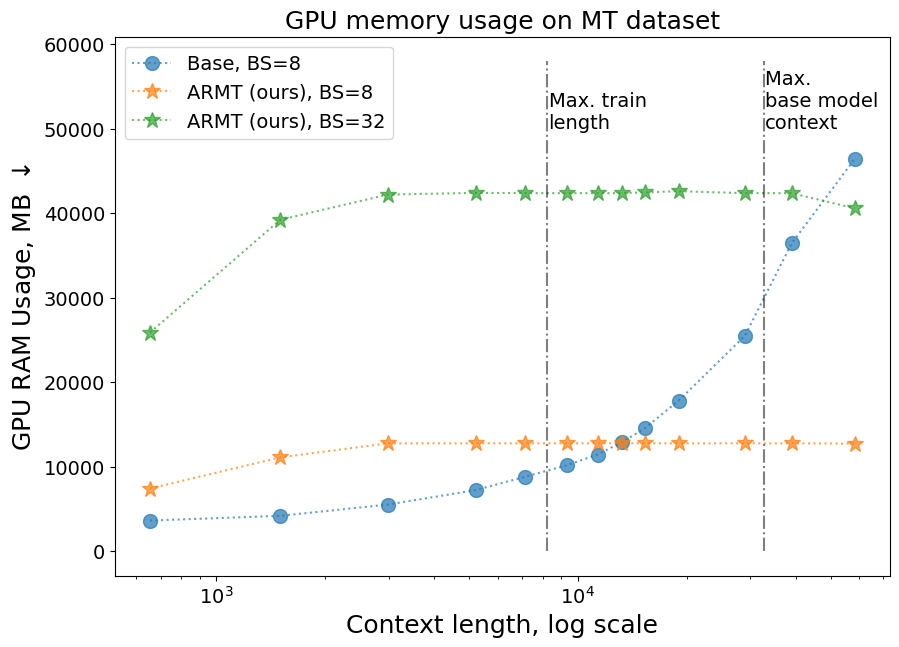

In [178]:

model_keys = [
    #"Gemma-3-1B-IT-MT-8k",
    #"ARMT-Gemma-3-1B-IT-MT-8k",
    "Gemma-3-1B-IT-MT-8k, batched-8",
    #"Gemma-3-1B-IT-MT-8k, batched-4",
    #"Mamba-1.3B gen64, MT, 8k",
    "ARMT-Gemma-3-1B-IT-MT-8k, batched",
    "ARMT-Gemma-3-1B-IT-MT-8k, batched-32",
    #"ARMT-Gemma-3-1B-IT-MT-8k, batched-4",
]
model_names = [
    #"Base, BS=1",
    #"ARMT (ours), BS=1",
    "Base, BS=8",
    #"Base, batched, 4 bs",
    #"Mamba",
    "ARMT (ours), BS=8",
    "ARMT (ours), BS=32",
    #"ARMT (ours), batched, 4 bs",
]
fig = plt.figure(figsize=(10,7))
cmap=mpl.colormaps["tab10"].colors
color_idx = [0,1,2, 8, 3]
x = times_bal_sup.T["lens"]#np.array([0, 1, 2, 4, 6, 8, 10, 12, 14, 16, 24, 32, 48, 64]) * 1024
main_ids = [0, 1]
global_fs = 18
#markers = ["o", "v", "s", "D", "*"]
markers = ["o", "*", "o", "*", "*"]
markers = ["o", "*", "*"]
for idx, (key, name) in enumerate(zip(model_keys, model_names)):
    ms = 10 if markers[idx] != "*" else 12
    plt.plot(x, list(times_bal_sup.T[f"{key}_mem"]), marker = markers[idx], ms=ms, alpha=0.7, linestyle=":",
             label=name, color=cmap[color_idx[idx]])
plt.vlines([32*1024], ymin=0.3, ymax=58000, linestyle="-.", color="k", alpha=0.5)
plt.vlines([8*1024], ymin=0.3, ymax=58000, linestyle="-.", color="k", alpha=0.5)
idx = 0
shift = [-100, -100, ]
train_sizes = [8*1024, 32*1024]
dnames = ["Max. train \nlength", "Max. \nbase model \ncontext"]
idx = 0
for x, y, text in zip(train_sizes, [50000] * len(train_sizes), dnames):
    plt.text(x-shift[idx], y-0.01, text, fontsize=14)
    idx += 1
plt.xscale('log') 
plt.xlabel("Context length, log scale", fontsize=global_fs)
plt.ylabel("GPU RAM Usage, MB $\\downarrow$", fontsize=global_fs)
plt.title("GPU memory usage on MT dataset", fontsize=global_fs)
plt.legend(fontsize=14, loc="upper left")
plt.tick_params(axis='both', which='major', labelsize=14)
plt.show()
fig.tight_layout()
fig.savefig("../../paper_results/main_res_mt_mem_usage_gemma_small_all_models_wo_bs1.pdf")

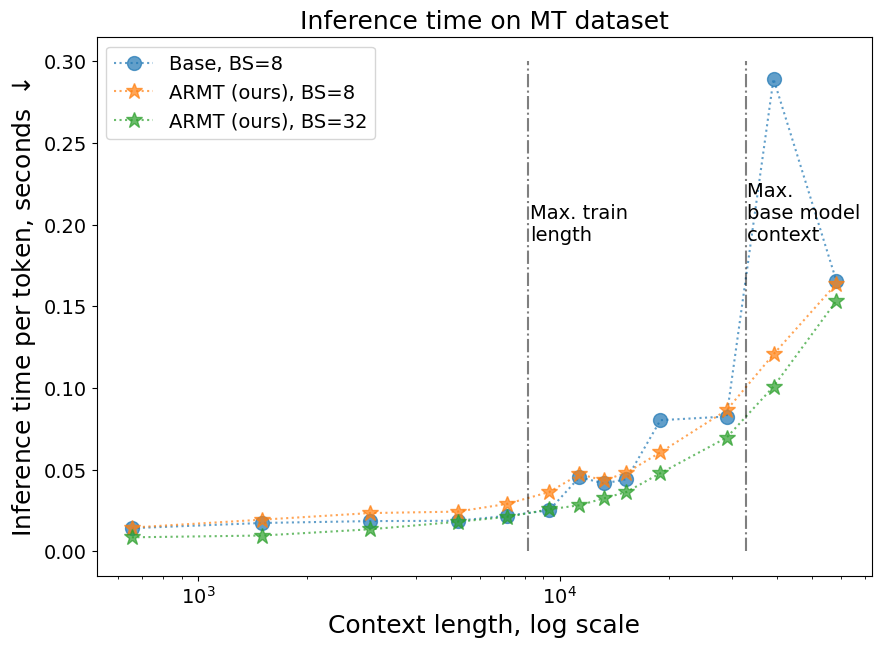

In [182]:

model_keys = [
    #"Gemma-3-1B-IT-MT-8k",
    #"ARMT-Gemma-3-1B-IT-MT-8k",
    "Gemma-3-1B-IT-MT-8k, batched-8",
    #"Gemma-3-1B-IT-MT-8k, batched-4",
    #"Mamba-1.3B gen64, MT, 8k",
    "ARMT-Gemma-3-1B-IT-MT-8k, batched",
    "ARMT-Gemma-3-1B-IT-MT-8k, batched-32",
    #"ARMT-Gemma-3-1B-IT-MT-8k, batched-4",
]
model_names = [
    #"Base, BS=1",
    #"ARMT (ours), BS=1",
    "Base, BS=8",
    #"Base, batched, 4 bs",
    #"Mamba",
    "ARMT (ours), BS=8",
    "ARMT (ours), BS=32",
    #"ARMT (ours), batched, 4 bs",
]
fig = plt.figure(figsize=(10,7))
cmap=mpl.colormaps["tab10"].colors
color_idx = [0,1,2, 8, 3]
x = times_bal_sup.T["lens"]#np.array([0, 1, 2, 4, 6, 8, 10, 12, 14, 16, 24, 32, 48, 64]) * 1024
main_ids = [0, 1]
global_fs = 18
#markers = ["o", "v", "s", "D", "*"]
markers = ["o", "*", "o", "*", "*"]
markers = ["o", "*", "*"]
for idx, (key, name) in enumerate(zip(model_keys, model_names)):
    ms = 10 if markers[idx] != "*" else 12
    plt.plot(x, list(times_bal_sup.T[f"{key}_time"]), marker = markers[idx], ms=ms, alpha=0.7, linestyle=":",
             label=name, color=cmap[color_idx[idx]])
plt.vlines([32*1024], ymin=0., ymax=0.3, linestyle="-.", color="k", alpha=0.5)
plt.vlines([8*1024], ymin=0., ymax=0.3, linestyle="-.", color="k", alpha=0.5)
idx = 0
shift = [-100, -100, ]
train_sizes = [8*1024, 32*1024]
dnames = ["Max. train \nlength", "Max. \nbase model \ncontext"]
idx = 0
for x, y, text in zip(train_sizes, [0.2] * len(train_sizes), dnames):
    plt.text(x-shift[idx], y-0.01, text, fontsize=14)
    idx += 1
plt.xscale('log') 
plt.xlabel("Context length, log scale", fontsize=global_fs)
plt.ylabel("Inference time per token, seconds $\\downarrow$", fontsize=global_fs)
plt.title("Inference time on MT dataset", fontsize=global_fs)
plt.legend(fontsize=14)
plt.tick_params(axis='both', which='major', labelsize=14)
plt.show()
fig.tight_layout()
fig.savefig("../../paper_results/main_res_mt_inf_time_gemma_small_all_models_wo_bs1.pdf")

### TIme with FA2

In [11]:
time_fnames = [
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/mem_empty_fa2_time_qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/base_model/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/google/gemma-3-1b-it/mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-05_50000/checkpoint-9800/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_override_attn_flash_attention_2_bs1.csv",
    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/mem_empty_fa2_time_qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/base_model/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/google/gemma-3-1b-it/mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-05_50000/checkpoint-9800/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_override_attn_flash_attention_2_bs8.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/mem_empty_fa2_time_qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/base_model/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-04_10000/checkpoint-9700/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_override_attn_flash_attention_2_bs8.csv",
    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/time_qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/base_model/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/google/gemma-3-1b-it/mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-05_50000/checkpoint-9800/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_bs4.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/mem_empty_fa2_time_qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-04_10000/checkpoint-200/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_override_attn_flash_attention_2_bs1.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/mem_empty_fa2_time_qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-04_10000/checkpoint-200/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_override_attn_flash_attention_2_bs8.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/mem_empty_fa2_time_qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-04_10000/checkpoint-200/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_override_attn_flash_attention_2_bs32.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/mem_empty_fa2_time_qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-04_10000/checkpoint-200/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_override_attn_flash_attention_2_bs64.csv",
    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/time_qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-04_10000/checkpoint-200/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_bs4.csv",
]
time_names = [
    "Gemma-3-1B-IT-MT-8k",
    "Gemma-3-1B-IT-MT-8k, batched-8",
    #"Gemma-3-1B-IT-MT-8k, batched-4",
    "ARMT-Gemma-3-1B-IT-MT-8k",
    "ARMT-Gemma-3-1B-IT-MT-8k, batched",
    "ARMT-Gemma-3-1B-IT-MT-8k, batched-32",
    "ARMT-Gemma-3-1B-IT-MT-8k, batched-64",
    #"ARMT-Gemma-3-1B-IT-MT-8k, batched-4",
]

In [12]:
# get times
time_res = {}
buf_fnames = time_fnames
buf_names = time_names
for path, name in zip(buf_fnames, buf_names):
    print(name)
    buf_df = pd.read_csv(path)
    print(len(buf_df))
    if path == buf_fnames[0]:
        time_res["question"] = buf_df["question"]
        time_res["context"] = buf_df["context"]
        time_res["target"] = buf_df["target"]
    time_res[f"{name}_time_base"] = buf_df["time"]
    time_res[f"{name}_answer"] = buf_df["output"]
    time_res[f"{name}_mem"] = buf_df["mem_usage"]
    time_res[f"{name}_ans_len"] = calc_ans_lengths(buf_df, "output", tokenizer)
    time_res[f"{name}_time"] = np.array(time_res[f"{name}_time_base"]) / np.array(time_res[f"{name}_ans_len"])
time_df = pd.DataFrame.from_dict(time_res)
time_df["lens"] = calc_lengths(time_df, tokenizer)

Gemma-3-1B-IT-MT-8k
1300
Gemma-3-1B-IT-MT-8k, batched-8
1300
ARMT-Gemma-3-1B-IT-MT-8k
1300
ARMT-Gemma-3-1B-IT-MT-8k, batched
1300
ARMT-Gemma-3-1B-IT-MT-8k, batched-32
1300
ARMT-Gemma-3-1B-IT-MT-8k, batched-64
1300


In [13]:
time_cols_only_bal_sup = [el for el in time_df.columns if ((("_time" in el and "_rougeLsum" not in el) or "len" in el or "mem" in el) and "_lens" not in el)]
results_time_bal_sup = {}
targs_time = time_df[time_cols_only_bal_sup]
starts = [0, 1024, 2048, 4096, 1024*6, 8192, 1024*10, 1024*12, 1024*14, 16384,  1024*24, 1024*32, 1024*48]
ends = [1024, 2048, 4096, 1024*6, 8192, 1024*10, 1024*12, 1024*14, 16384, 1024*24, 1024*32, 1024*48, 65536]
for start, end in zip(starts, ends):
    buf_res = targs_time[(targs_time["lens"] > start) & (targs_time["lens"] < end)]
    #print(start, end, len(buf_res))
    #print(buf_res.mean())
    results_time_bal_sup[f"{str(start//1000)}k_{str(end//1000)}k"] = buf_res.mean()

In [14]:
times_bal_sup = pd.concat(results_time_bal_sup, axis=1)
#times_bal_sup = times_bal_sup.drop("lens")
times_bal_sup

,0k_1k,1k_2k,2k_4k,4k_6k,6k_8k,8k_10k,10k_12k,12k_14k,14k_16k,16k_24k,24k_32k,32k_49k,49k_65k
Gemma-3-1B-IT-MT-8k_time_base,0.471034,0.524791,0.458779,0.539983,0.503727,0.494834,0.506030,0.508336,0.482635,0.491860,0.823905,0.867688,9.088134
Gemma-3-1B-IT-MT-8k_mem,2858.615385,2928.057143,3062.849057,3253.726027,3429.804348,3627.950617,3782.747253,3949.000000,4161.303371,4465.180556,5372.772277,6296.104348,7919.900990
Gemma-3-1B-IT-MT-8k_ans_len,8.500000,9.619048,8.132075,9.410959,8.315217,7.617284,7.373626,6.914894,6.067416,5.673611,10.633663,8.826087,178.574257
Gemma-3-1B-IT-MT-8k_time,0.056639,0.056252,0.057635,0.059399,0.062600,0.066807,0.072054,0.081184,0.084821,0.094808,0.114513,0.152069,0.102093
"Gemma-3-1B-IT-MT-8k, batched-8_time_base",0.105923,0.135230,0.134375,0.146037,0.158744,0.176921,0.267379,0.255527,0.239018,0.278791,0.392554,0.538504,0.795948
"Gemma-3-1B-IT-MT-8k, batched-8_mem",3642.846154,4201.733333,5535.018868,7246.493151,8836.130435,10210.740741,11458.549451,12934.978723,14543.483146,17830.208333,25486.099010,35755.200000,46853.089109
"Gemma-3-1B-IT-MT-8k, batched-8_ans_len",8.538462,9.885714,8.500000,9.178082,8.358696,7.851852,7.934066,11.223404,8.123596,7.979167,7.722772,5.313043,8.118812
"Gemma-3-1B-IT-MT-8k, batched-8_time",0.013991,0.017381,0.018354,0.019104,0.021498,0.024863,0.037473,0.030804,0.033873,0.042194,0.066423,0.163043,0.199931
ARMT-Gemma-3-1B-IT-MT-8k_time_base,0.625810,0.626744,0.667126,0.862197,0.954591,1.058635,1.248730,1.420642,1.532687,1.783597,2.756553,3.157436,4.630750
ARMT-Gemma-3-1B-IT-MT-8k_mem,3136.589744,3711.123810,4220.415094,4220.219178,4220.478261,4220.049383,4220.175824,4220.446809,4220.337079,4220.583333,4220.316832,4220.417391,4220.039604


In [16]:
x=1

In [17]:
import matplotlib.pyplot as plt
import matplotlib as mpl


#### Small pictures for poster

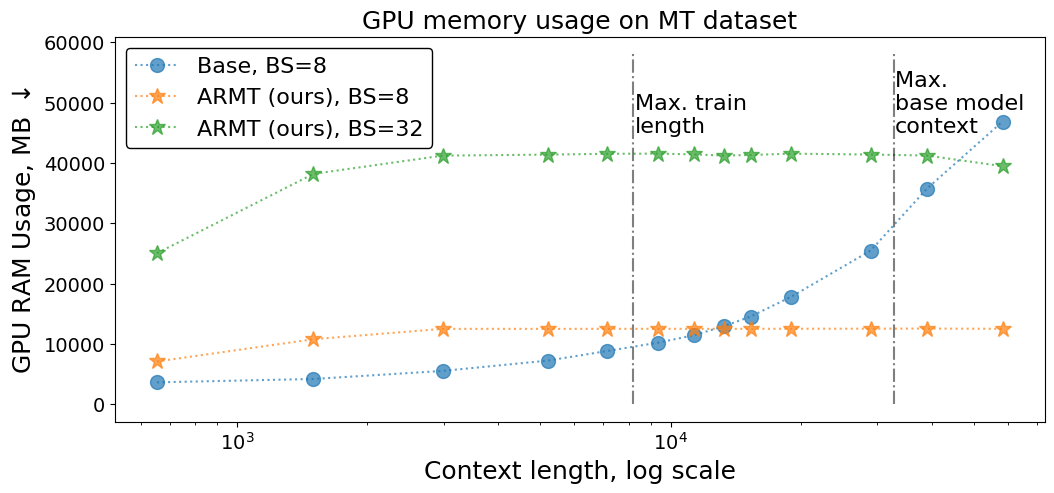

In [25]:

model_keys = [
    #"Gemma-3-1B-IT-MT-8k",
    #"ARMT-Gemma-3-1B-IT-MT-8k",
    "Gemma-3-1B-IT-MT-8k, batched-8",
    #"Gemma-3-1B-IT-MT-8k, batched-4",
    #"Mamba-1.3B gen64, MT, 8k",
    "ARMT-Gemma-3-1B-IT-MT-8k, batched",
    "ARMT-Gemma-3-1B-IT-MT-8k, batched-32",
    #"ARMT-Gemma-3-1B-IT-MT-8k, batched-4",
]
model_names = [
    #"Base, BS=1",
    #"ARMT (ours), BS=1",
    "Base, BS=8",
    #"Base, batched, 4 bs",
    #"Mamba",
    "ARMT (ours), BS=8",
    "ARMT (ours), BS=32",
    #"ARMT (ours), batched, 4 bs",
]
fig = plt.figure(figsize=(12,5))
cmap=mpl.colormaps["tab10"].colors
color_idx = [0,1,2, 8, 3]
x = times_bal_sup.T["lens"]#np.array([0, 1, 2, 4, 6, 8, 10, 12, 14, 16, 24, 32, 48, 64]) * 1024
main_ids = [0, 1]
global_fs = 18
#markers = ["o", "v", "s", "D", "*"]
markers = ["o", "*", "o", "*", "*"]
markers = ["o", "*", "*"]
for idx, (key, name) in enumerate(zip(model_keys, model_names)):
    ms = 10 if markers[idx] != "*" else 12
    plt.plot(x, list(times_bal_sup.T[f"{key}_mem"]), marker = markers[idx], ms=ms, alpha=0.7, linestyle=":",
             label=name, color=cmap[color_idx[idx]])
plt.vlines([32*1024], ymin=0.3, ymax=58000, linestyle="-.", color="k", alpha=0.5)
plt.vlines([8*1024], ymin=0.3, ymax=58000, linestyle="-.", color="k", alpha=0.5)
idx = 0
shift = [-100, -100, ]
train_sizes = [8*1024, 32*1024]
dnames = ["Max. train \nlength", "Max. \nbase model \ncontext"]
idx = 0
for x, y, text in zip(train_sizes, [45000] * len(train_sizes), dnames):
    plt.text(x-shift[idx], y-0.01, text, fontsize=16)
    idx += 1
plt.xscale('log') 
plt.xlabel("Context length, log scale", fontsize=global_fs)
plt.ylabel("GPU RAM Usage, MB $\\downarrow$", fontsize=global_fs)
plt.title("GPU memory usage on MT dataset", fontsize=global_fs)
plt.legend(fontsize=14, loc="upper left")
legend = plt.legend(loc="upper left", fontsize=16, edgecolor="black")
legend.get_frame().set_alpha(None)
legend.get_frame().set_facecolor((0, 0, 1, 0.001))
plt.tick_params(axis='both', which='major', labelsize=14)
plt.show()
fig.tight_layout()
fig.savefig("../../paper_results/main_res_mt_mem_usage_gemma_small_all_models_flash_attn_poster.pdf", transparent=True)

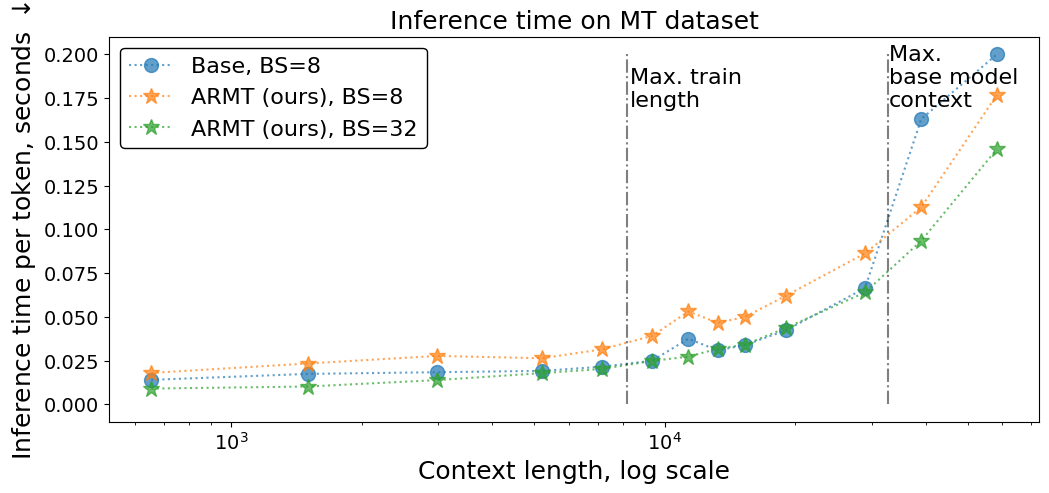

In [30]:

model_keys = [
    #"Gemma-3-1B-IT-MT-8k",
    #"ARMT-Gemma-3-1B-IT-MT-8k",
    "Gemma-3-1B-IT-MT-8k, batched-8",
    #"Gemma-3-1B-IT-MT-8k, batched-4",
    #"Mamba-1.3B gen64, MT, 8k",
    "ARMT-Gemma-3-1B-IT-MT-8k, batched",
    "ARMT-Gemma-3-1B-IT-MT-8k, batched-32",
    #"ARMT-Gemma-3-1B-IT-MT-8k, batched-4",
]
model_names = [
    #"Base, BS=1",
    #"ARMT (ours), BS=1",
    "Base, BS=8",
    #"Base, batched, 4 bs",
    #"Mamba",
    "ARMT (ours), BS=8",
    "ARMT (ours), BS=32",
    #"ARMT (ours), batched, 4 bs",
]
fig = plt.figure(figsize=(12,5))
cmap=mpl.colormaps["tab10"].colors
color_idx = [0,1,2, 8, 3]
x = times_bal_sup.T["lens"]#np.array([0, 1, 2, 4, 6, 8, 10, 12, 14, 16, 24, 32, 48, 64]) * 1024
main_ids = [0, 1]
global_fs = 18
#markers = ["o", "v", "s", "D", "*"]
markers = ["o", "*", "o", "*", "*"]
markers = ["o", "*", "*"]
tts_multiplier = [8, 8, 32]
for idx, (key, name) in enumerate(zip(model_keys, model_names)):
    ms = 10 if markers[idx] != "*" else 12
    plt.plot(x, list(times_bal_sup.T[f"{key}_time"]), marker = markers[idx], ms=ms, alpha=0.7, linestyle=":",
             label=name, color=cmap[color_idx[idx]])
plt.vlines([32*1024], ymin=0., ymax=0.2, linestyle="-.", color="k", alpha=0.5)
plt.vlines([8*1024], ymin=0., ymax=0.2, linestyle="-.", color="k", alpha=0.5)
idx = 0
shift = [-100, -100, ]
train_sizes = [8*1024, 32*1024]
dnames = ["Max. train \nlength", "Max. \nbase model \ncontext"]
idx = 0
for x, y, text in zip(train_sizes, [0.18] * len(train_sizes), dnames):
    plt.text(x-shift[idx], y-0.01, text, fontsize=16)
    idx += 1
plt.xscale('log') 
plt.xlabel("Context length, log scale", fontsize=global_fs)
plt.ylabel("Inference time per token, seconds $\\downarrow$", fontsize=global_fs)
plt.title("Inference time on MT dataset", fontsize=global_fs)
plt.legend(fontsize=14)

legend = plt.legend(loc="upper left", fontsize=16, edgecolor="black")
legend.get_frame().set_alpha(None)
legend.get_frame().set_facecolor((0, 0, 1, 0.001))
plt.tick_params(axis='both', which='major', labelsize=14)
plt.show()
fig.tight_layout()
fig.savefig("../../paper_results/main_res_mt_inf_time_gemma_small_all_models_flash_attn_poster.pdf", transparent=True)

#### Normal pics for paper

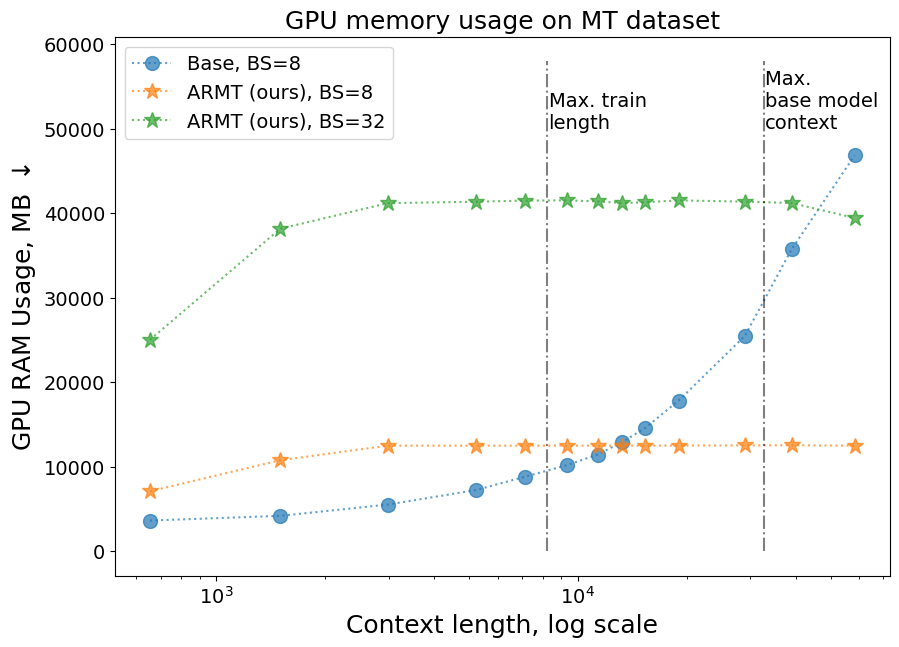

In [231]:

model_keys = [
    #"Gemma-3-1B-IT-MT-8k",
    #"ARMT-Gemma-3-1B-IT-MT-8k",
    "Gemma-3-1B-IT-MT-8k, batched-8",
    #"Gemma-3-1B-IT-MT-8k, batched-4",
    #"Mamba-1.3B gen64, MT, 8k",
    "ARMT-Gemma-3-1B-IT-MT-8k, batched",
    "ARMT-Gemma-3-1B-IT-MT-8k, batched-32",
    #"ARMT-Gemma-3-1B-IT-MT-8k, batched-4",
]
model_names = [
    #"Base, BS=1",
    #"ARMT (ours), BS=1",
    "Base, BS=8",
    #"Base, batched, 4 bs",
    #"Mamba",
    "ARMT (ours), BS=8",
    "ARMT (ours), BS=32",
    #"ARMT (ours), batched, 4 bs",
]
fig = plt.figure(figsize=(10,7))
cmap=mpl.colormaps["tab10"].colors
color_idx = [0,1,2, 8, 3]
x = times_bal_sup.T["lens"]#np.array([0, 1, 2, 4, 6, 8, 10, 12, 14, 16, 24, 32, 48, 64]) * 1024
main_ids = [0, 1]
global_fs = 18
#markers = ["o", "v", "s", "D", "*"]
markers = ["o", "*", "o", "*", "*"]
markers = ["o", "*", "*"]
for idx, (key, name) in enumerate(zip(model_keys, model_names)):
    ms = 10 if markers[idx] != "*" else 12
    plt.plot(x, list(times_bal_sup.T[f"{key}_mem"]), marker = markers[idx], ms=ms, alpha=0.7, linestyle=":",
             label=name, color=cmap[color_idx[idx]])
plt.vlines([32*1024], ymin=0.3, ymax=58000, linestyle="-.", color="k", alpha=0.5)
plt.vlines([8*1024], ymin=0.3, ymax=58000, linestyle="-.", color="k", alpha=0.5)
idx = 0
shift = [-100, -100, ]
train_sizes = [8*1024, 32*1024]
dnames = ["Max. train \nlength", "Max. \nbase model \ncontext"]
idx = 0
for x, y, text in zip(train_sizes, [50000] * len(train_sizes), dnames):
    plt.text(x-shift[idx], y-0.01, text, fontsize=14)
    idx += 1
plt.xscale('log') 
plt.xlabel("Context length, log scale", fontsize=global_fs)
plt.ylabel("GPU RAM Usage, MB $\\downarrow$", fontsize=global_fs)
plt.title("GPU memory usage on MT dataset", fontsize=global_fs)
plt.legend(fontsize=14, loc="upper left")
plt.tick_params(axis='both', which='major', labelsize=14)
plt.show()
fig.tight_layout()
fig.savefig("../../paper_results/main_res_mt_mem_usage_gemma_small_all_models_flash_attn.pdf")

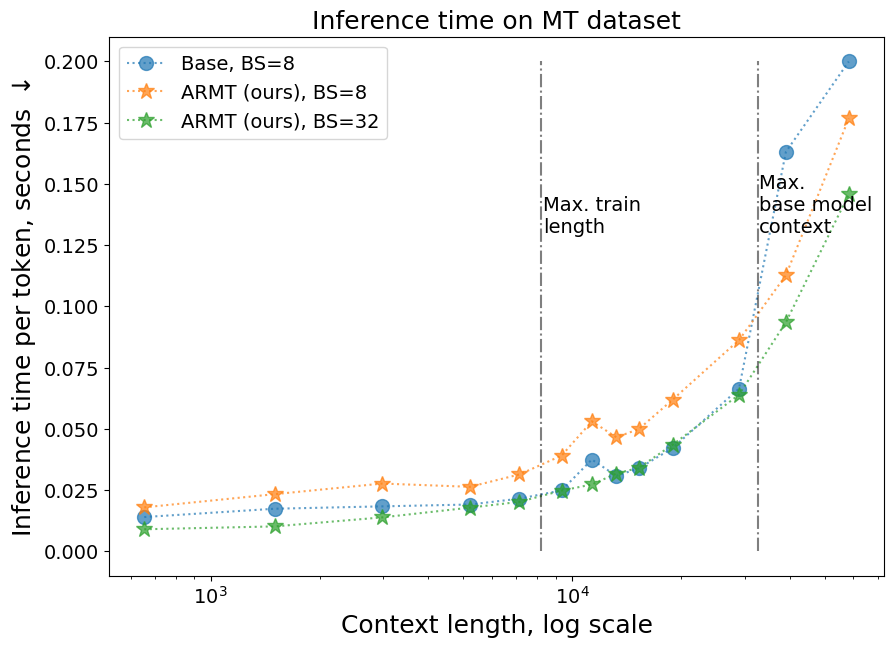

In [234]:

model_keys = [
    #"Gemma-3-1B-IT-MT-8k",
    #"ARMT-Gemma-3-1B-IT-MT-8k",
    "Gemma-3-1B-IT-MT-8k, batched-8",
    #"Gemma-3-1B-IT-MT-8k, batched-4",
    #"Mamba-1.3B gen64, MT, 8k",
    "ARMT-Gemma-3-1B-IT-MT-8k, batched",
    "ARMT-Gemma-3-1B-IT-MT-8k, batched-32",
    #"ARMT-Gemma-3-1B-IT-MT-8k, batched-4",
]
model_names = [
    #"Base, BS=1",
    #"ARMT (ours), BS=1",
    "Base, BS=8",
    #"Base, batched, 4 bs",
    #"Mamba",
    "ARMT (ours), BS=8",
    "ARMT (ours), BS=32",
    #"ARMT (ours), batched, 4 bs",
]
fig = plt.figure(figsize=(10,7))
cmap=mpl.colormaps["tab10"].colors
color_idx = [0,1,2, 8, 3]
x = times_bal_sup.T["lens"]#np.array([0, 1, 2, 4, 6, 8, 10, 12, 14, 16, 24, 32, 48, 64]) * 1024
main_ids = [0, 1]
global_fs = 18
#markers = ["o", "v", "s", "D", "*"]
markers = ["o", "*", "o", "*", "*"]
markers = ["o", "*", "*"]
tts_multiplier = [8, 8, 32]
for idx, (key, name) in enumerate(zip(model_keys, model_names)):
    ms = 10 if markers[idx] != "*" else 12
    plt.plot(x, list(times_bal_sup.T[f"{key}_time"]), marker = markers[idx], ms=ms, alpha=0.7, linestyle=":",
             label=name, color=cmap[color_idx[idx]])
plt.vlines([32*1024], ymin=0., ymax=0.2, linestyle="-.", color="k", alpha=0.5)
plt.vlines([8*1024], ymin=0., ymax=0.2, linestyle="-.", color="k", alpha=0.5)
idx = 0
shift = [-100, -100, ]
train_sizes = [8*1024, 32*1024]
dnames = ["Max. train \nlength", "Max. \nbase model \ncontext"]
idx = 0
for x, y, text in zip(train_sizes, [0.14] * len(train_sizes), dnames):
    plt.text(x-shift[idx], y-0.01, text, fontsize=14)
    idx += 1
plt.xscale('log') 
plt.xlabel("Context length, log scale", fontsize=global_fs)
plt.ylabel("Inference time per token, seconds $\\downarrow$", fontsize=global_fs)
plt.title("Inference time on MT dataset", fontsize=global_fs)
plt.legend(fontsize=14)
plt.tick_params(axis='both', which='major', labelsize=14)
plt.show()
fig.tight_layout()
fig.savefig("../../paper_results/main_res_mt_inf_time_gemma_small_all_models_flash_attn.pdf")

Base, BS=8 [71.4742586  57.53366066 54.48377086 52.34372907 46.51542707 40.22106617
 26.6858541  32.46284039 29.52165966 23.69994647 15.05504927  6.13334778
  5.00172665]
ARMT (ours), BS=8 [55.72724309 42.86927314 36.15184537 37.97983983 31.86472466 25.59412421
 18.84325934 21.47486228 20.04527736 16.13801104 11.59633556  8.87545559
  5.66050697]
ARMT (ours), BS=32 [111.08902301  98.31667894  72.20358764  56.06230292  49.52514314
  40.33634307  36.66394738  31.50350275  29.3476444   22.95766967
  15.64120289  10.69684769   6.86193697]


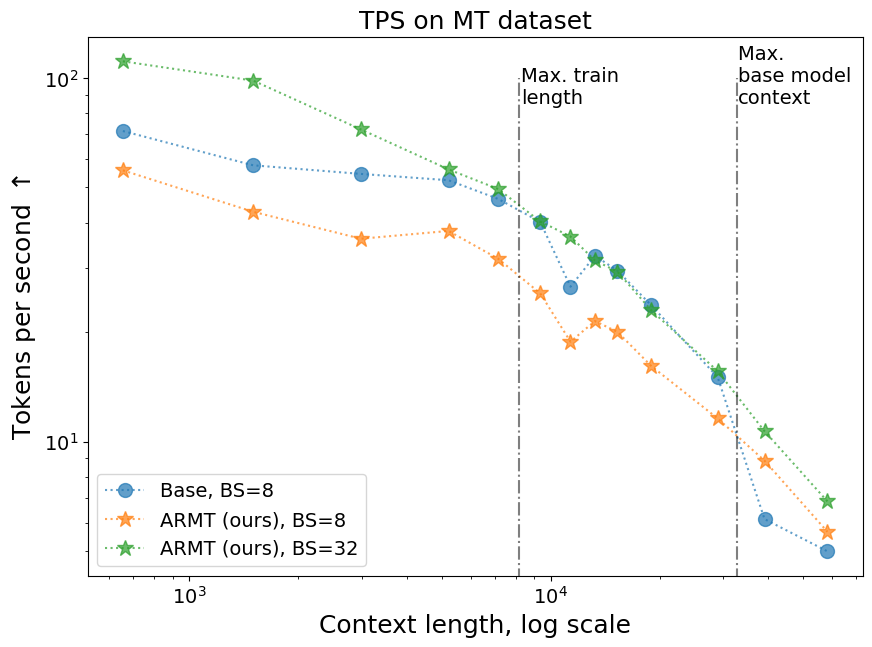

In [253]:

model_keys = [
    #"Gemma-3-1B-IT-MT-8k",
    #"ARMT-Gemma-3-1B-IT-MT-8k",
    "Gemma-3-1B-IT-MT-8k, batched-8",
    #"Gemma-3-1B-IT-MT-8k, batched-4",
    #"Mamba-1.3B gen64, MT, 8k",
    "ARMT-Gemma-3-1B-IT-MT-8k, batched",
    "ARMT-Gemma-3-1B-IT-MT-8k, batched-32",
    #"ARMT-Gemma-3-1B-IT-MT-8k, batched-64",
    #"ARMT-Gemma-3-1B-IT-MT-8k, batched-4",
]
model_names = [
    #"Base, BS=1",
    #"ARMT (ours), BS=1",
    "Base, BS=8",
    #"Base, batched, 4 bs",
    #"Mamba",
    "ARMT (ours), BS=8",
    "ARMT (ours), BS=32",
    #"ARMT (ours), BS=64",
    #"ARMT (ours), batched, 4 bs",
]
fig = plt.figure(figsize=(10,7))
cmap=mpl.colormaps["tab10"].colors
color_idx = [0,1,2, 8, 3]
x = times_bal_sup.T["lens"]#np.array([0, 1, 2, 4, 6, 8, 10, 12, 14, 16, 24, 32, 48, 64]) * 1024
main_ids = [0, 1]
global_fs = 18
#markers = ["o", "v", "s", "D", "*"]
markers = ["o", "*", "o", "*", "*"]
markers = ["o", "*", "*", "*"]
tts_multiplier = [8, 8, 32]
for idx, (key, name) in enumerate(zip(model_keys, model_names)):
    ms = 10 if markers[idx] != "*" else 12
    plt.plot(x, 1 / np.array(times_bal_sup.T[f"{key}_time"]), marker = markers[idx], ms=ms, alpha=0.7, linestyle=":",
             label=name, color=cmap[color_idx[idx]])
    print(name, 1 / np.array(times_bal_sup.T[f"{key}_time"]))
plt.vlines([32*1024], ymin=0., ymax=100, linestyle="-.", color="k", alpha=0.5)
plt.vlines([8*1024], ymin=0., ymax=100, linestyle="-.", color="k", alpha=0.5)
idx = 0
shift = [-100, -100, ]
train_sizes = [8*1024, 32*1024]
dnames = ["Max. train \nlength", "Max. \nbase model \ncontext"]
idx = 0
for x, y, text in zip(train_sizes, [85] * len(train_sizes), dnames):
    plt.text(x-shift[idx], y-0.01, text, fontsize=14)
    idx += 1
plt.xscale('log')
plt.yscale('log')
plt.xlabel("Context length, log scale", fontsize=global_fs)
plt.ylabel("Tokens per second $\\uparrow$", fontsize=global_fs)
plt.title("TPS on MT dataset", fontsize=global_fs)
plt.legend(fontsize=14)
plt.tick_params(axis='both', which='major', labelsize=14)
plt.show()
fig.tight_layout()
#fig.savefig("../../paper_results/main_res_mt_inf_time_gemma_small_all_models_flash_attn.pdf")

In [27]:
# get times
use_ids = [24, 15,19,22, 83,84,128]
time_res = {}
buf_fnames = [add_fnames[idx] for idx in use_ids]
buf_names = [add_mod_names[idx] for idx in use_ids]
for path, name in zip(buf_fnames, buf_names):
    buf_df = pd.read_csv(path)
    if path == buf_fnames[0]:
        time_res["question"] = buf_df["question"]
        time_res["context"] = buf_df["context"]
        time_res["target"] = buf_df["target"]
    time_res[f"{name}_time_base"] = buf_df["time"]
    time_res[f"{name}_answer"] = buf_df["output"]
    time_res[f"{name}_ans_len"] = calc_ans_lengths(buf_df, "output", tokenizer)
    time_res[f"{name}_time"] = np.array(time_res[f"{name}_time_base"]) / np.array(time_res[f"{name}_ans_len"])
time_df = pd.DataFrame.from_dict(time_res)
time_df["lens"] = calc_lengths(time_df, tokenizer)

In [28]:
time_cols_only_bal_sup = [el for el in time_df.columns if ((("_time" in el and "_rougeLsum" not in el) or "len" in el) and "_lens" not in el)]
results_time_bal_sup = {}
targs_time = time_df[time_cols_only_bal_sup]
starts = [0, 1024, 2048, 4096, 1024*6, 8192, 1024*10, 1024*12, 1024*14, 16384,  1024*24, 1024*32, 1024*48]
ends = [1024, 2048, 4096, 1024*6, 8192, 1024*10, 1024*12, 1024*14, 16384, 1024*24, 1024*32, 1024*48, 65536]
for start, end in zip(starts, ends):
    buf_res = targs_time[(targs_time["lens"] > start) & (targs_time["lens"] < end)]
    #print(start, end, len(buf_res))
    #print(buf_res.mean())
    results_time_bal_sup[f"{str(start//1000)}k_{str(end//1000)}k"] = buf_res.mean()

In [29]:
times_bal_sup = pd.concat(results_time_bal_sup, axis=1)
#times_bal_sup = times_bal_sup.drop("lens")
times_bal_sup

,0k_1k,1k_2k,2k_4k,4k_6k,6k_8k,8k_10k,10k_12k,12k_14k,14k_16k,16k_24k,24k_32k,32k_49k,49k_65k
Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15-mask-shift-no-group-1e4-bs64-9700_time_base,0.771766,0.871496,0.773635,0.848160,0.818392,0.823194,0.852830,1.127606,0.932237,0.970605,1.110368,1.086019,1.668436
Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15-mask-shift-no-group-1e4-bs64-9700_ans_len,8.538462,9.952381,8.500000,9.178082,8.358696,7.851852,7.934066,11.223404,8.123596,7.951389,7.722772,5.295652,8.118812
Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15-mask-shift-no-group-1e4-bs64-9700_time,0.092574,0.090591,0.093574,0.095596,0.100666,0.107253,0.110779,0.112643,0.120818,0.132021,0.164403,0.275497,0.341465
ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-1e4-bs64-7000_time_base,0.584302,0.623816,0.634672,1.192052,1.205505,2.729400,3.954268,3.709499,4.167283,7.448370,8.711536,11.290483,13.360554
ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-1e4-bs64-7000_ans_len,11.807692,9.723810,8.075472,15.150685,13.706522,44.271605,64.527473,54.521277,65.325843,127.298611,129.871287,173.539130,190.099010
ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-1e4-bs64-7000_time,0.050438,0.068004,0.082603,0.110978,0.124682,0.140782,0.151849,0.166231,0.163969,0.151684,0.306354,0.413035,0.416702
ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-1e4-bs64_time_base,0.597404,0.608125,0.638393,0.839401,0.939518,1.038274,1.208997,1.372459,1.486218,1.730281,2.804008,3.218764,4.473386
ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-1e4-bs64_ans_len,11.807692,9.276190,7.924528,8.876712,8.336957,7.456790,7.945055,8.702128,7.955056,7.833333,15.346535,10.182609,9.960396
ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-1e4-bs64_time,0.051284,0.069430,0.084225,0.104421,0.122966,0.146007,0.163743,0.177144,0.204038,0.238788,0.326307,0.426361,0.663915
ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-3e5-bs64-long-val-from-high-lr-final_time_base,0.603120,0.640426,0.640427,0.831849,1.064682,1.022964,1.180979,1.356184,1.451698,1.798247,2.400984,3.065396,4.403115


## Build all

In [36]:
buf_res = emss.iloc[np.arange(len(emss))].round(3)#,67,68]].round(3)

In [37]:
cumulative_score = (buf_res[buf_res.columns[1:]] * support / sum(support)).sum(axis=1)
cumulative_score_id = (buf_res[buf_res.columns[1:6]] * support[:5] / sum(support[:5])).sum(axis=1)
cumulative_score_ood = (buf_res[buf_res.columns[6:]] * support[5:] / sum(support[5:])).sum(axis=1)
cumulative_score_ood_long = (buf_res[buf_res.columns[12:]] * support[11:] / sum(support[11:])).sum(axis=1)

In [38]:
buf_res["In-Domain (0k-8k)"] = cumulative_score_id
buf_res["OOD (8k-65k)"] = cumulative_score_ood
buf_res["Long-OOD (32k-65k)"] = cumulative_score_ood_long
buf_res["Full (0k-65k)"] = cumulative_score

In [39]:
buf_res.columns[1:6]

Index(['0k_1k', '1k_2k', '2k_4k', '4k_6k', '6k_8k'], dtype='object')

In [40]:
support[:5]

[78, 105, 106, 73, 92]

In [41]:
s = buf_res.style
for l0 in [0,16,40,44,41,47,52,58,61, 63, 69]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [74,8,46,42,53, 64, 80]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

,Model,0k_1k,1k_2k,2k_4k,4k_6k,6k_8k,8k_10k,10k_12k,12k_14k,14k_16k,16k_24k,24k_32k,32k_49k,49k_65k,In-Domain (0k-8k),OOD (8k-65k),Long-OOD (32k-65k),Full (0k-65k)
0,Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15-mask-shift,0.744,0.724,0.670,0.658,0.859,0.802,0.758,0.681,0.640,0.646,0.406,0.278,0.069,0.732,0.524,0.180,0.598
1,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift,0.692,0.543,0.557,0.493,0.565,0.506,0.440,0.436,0.416,0.444,0.426,0.478,0.416,0.568,0.445,0.449,0.489
2,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift,0.692,0.533,0.538,0.493,0.587,0.543,0.505,0.426,0.427,0.479,0.436,0.478,0.426,0.566,0.464,0.454,0.501
3,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-no-cl-assist-mask-left-pad-es15_no_sw-mask-shift,0.667,0.562,0.547,0.507,0.587,0.580,0.505,0.468,0.472,0.500,0.475,0.513,0.416,0.573,0.490,0.468,0.520
4,Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15-mask-shift-50k,0.718,0.771,0.679,0.658,0.804,0.827,0.714,0.585,0.584,0.507,0.347,0.270,0.020,0.729,0.466,0.153,0.560
5,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift (from 2s inst),0.705,0.638,0.585,0.548,0.554,0.580,0.527,0.404,0.472,0.458,0.396,0.478,0.426,0.606,0.464,0.454,0.515
6,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift (from 2s inst),0.705,0.600,0.557,0.534,0.543,0.568,0.516,0.404,0.461,0.486,0.436,0.452,0.455,0.586,0.470,0.453,0.512
7,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-no-cl-assist-mask-left-pad-es15_no_sw-mask-shift-50k,0.705,0.505,0.566,0.521,0.576,0.531,0.484,0.415,0.472,0.493,0.436,0.487,0.356,0.571,0.460,0.426,0.499
8,Gemma3-1b-IT-all-lin-128-256-MT-8s-assist-mask-left-pad-es15-mask-shift,0.756,0.771,0.698,0.671,0.848,0.840,0.758,0.777,0.708,0.688,0.554,0.339,0.129,0.751,0.588,0.241,0.646
9,ARMT-Gemma3-1b-IT-all-lin-128-256-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift,0.731,0.581,0.566,0.493,0.565,0.543,0.473,0.426,0.449,0.486,0.376,0.435,0.406,0.586,0.449,0.421,0.498


## Prepare paper results

In [74]:
#buf_res = emss.iloc[[24] + [15,19,22,25,26, 27,28,29,30]  + list(range(31, 31+26)) + [57,58,59,60] + [61,62,63,64,65, 66, 67, 68,69,70, 71,72,73] + [74,75,76, 77,78,79, 80,82, 86,87,88,89] + list(range(90, 90+32)) + [83,84,85, 122, 123,124,125, 126, 127, 128,129, 130,131,132] + list(range(133, 133+26)) + list(range(159, 159+26)) + [187, 190, 188,189,191,192,193,194,  197,199,204]].round(3)#,67,68]].round(3)
buf_res = emss.iloc[[24] + [15,18,22,25,26, 27,28,29,30]  + list(range(31, 31+26)) + [57,58,59,60] + [61,62,63,64,65, 66, 67, 68,69,70, 71,72,73] + [74,75,76, 77,78,79, 80,82, 86,87,88,89] + list(range(90, 90+32)) + [83,84,85, 122, 123,124,125, 126, 127, 128,129, 130,131,132] + list(range(133, 133+26)) + list(range(159, 159+26)) + [187, 190, 188,189,191,192,193,194,  197,199,204]].round(3)#,67,68]].round(3)

In [75]:
cumulative_score = (buf_res[buf_res.columns[1:]] * support / sum(support)).sum(axis=1)
cumulative_score_id = (buf_res[buf_res.columns[1:6]] * support[:5] / sum(support[:5])).sum(axis=1)
cumulative_score_ood = (buf_res[buf_res.columns[6:]] * support[5:] / sum(support[5:])).sum(axis=1)
cumulative_score_ood_long = (buf_res[buf_res.columns[12:]] * support[11:] / sum(support[11:])).sum(axis=1)

In [76]:
buf_res["In-Domain (0k-8k)"] = cumulative_score_id
buf_res["OOD (8k-65k)"] = cumulative_score_ood
buf_res["Long-OOD (32k-65k)"] = cumulative_score_ood_long
buf_res["Full (0k-65k)"] = cumulative_score

In [77]:
new_names = [
    "Gemma-3-1B-IT, MT, 8k",
    "ARMT-Gemma-3-1B-IT, MT, 2k",
    "ARMT-Gemma-3-1B-IT, MT, 4k",
    "ARMT-Gemma-3-1B-IT, MT, 8k",
    "Gemma-3-1B-IT, base prompt",
    "Gemma-3-1B-IT, instructive prompt",

    "ARMT-Gemma-3-1B-IT, MT, 8k, 0-6 layers removed",
    "ARMT-Gemma-3-1B-IT, MT, 8k, 7-12 layers removed",
    "ARMT-Gemma-3-1B-IT, MT, 8k, 13-18 layers removed",
    "ARMT-Gemma-3-1B-IT, MT, 8k, 19-25 layers removed",
]
new_names += [f"W/o layer {idx}" for idx in range(26)]
new_names += [
    "ARMT-Gemma-3-1B-IT, MT, 8k, 0-12 layers removed",
    "ARMT-Gemma-3-1B-IT, MT, 8k, 13-26 layers removed",
    "ARMT-Gemma-3-1B-IT, MT, 8k, 14th layer used",
    "ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers used",

    "ARMT-Gemma-3-1B-IT, MT, 2k, top-4 layers trained",
    "ARMT-Gemma-3-1B-IT, MT, 4k, top-4 layers trained",

    "ARMT-Gemma-3-1B-IT, MT-script-version, 2k",
    "ARMT-Gemma-3-1B-IT, MT-script-version, 4k",
    "ARMT-Gemma-3-1B-IT, MT-script-version, 8k",
    "ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers trained 2400",
    "ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers trained",

    "ARMT-Gemma-3-1B-IT, MT, 2k, top-5 layers trained",
    "ARMT-Gemma-3-1B-IT, MT, 4k, top-5 layers trained",
    "ARMT-Gemma-3-1B-IT, MT, 8k, top-5 layers trained",

    "Mamba-1.3B base",
    "Mamba-1.3B gen16, MT, 8k",
    "Mamba-1.3B gen64, MT, 8k",

    "ARMT-SmolLM-2-360M-IT, MT, 2k",
    "ARMT-SmolLM-2-360M-IT, MT, 4k",
    "ARMT-SmolLM-2-360M-IT, MT, 8k",

    "ARMT-SmolLM-2-360M-IT, MT, 2k, top-6 layers trained",
    "ARMT-SmolLM-2-360M-IT, MT, 4k, top-6 layers trained",
    "ARMT-SmolLM-2-360M-IT, MT, 8k, top-6 layers trained",

    "SmolLM-2-360M-IT, base prompt",
    "SmolLM-2-360M-IT, MT, 8k",

    "ARMT-SmolLM-2-360M-IT, MT, 8k, 0-7 layers removed",
    "ARMT-SmolLM-2-360M-IT, MT, 8k, 8-15 layers removed",
    "ARMT-SmolLM-2-360M-IT, MT, 8k, 16-23 layers removed",
    "ARMT-SmolLM-2-360M-IT, MT, 8k, 24-31 layers removed",
]
new_names += [f"SLM,W/o layer {idx}" for idx in range(32)]
new_names += [

    "ARMT-Gemma-3-1B-IT, MT, 2k, from pretrained",
    "ARMT-Gemma-3-1B-IT, MT, 4k, from pretrained",
    "ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained-prelim",

    "ARMT-SmolLM-2-360M-IT, MT, 8k, top-4 layers used",
    "ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained-prelim-v2",
    "ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained-no-cl-prelim",
    "ARMT-SmolLM-2-360M-IT, MT, 8k, top-1 layer used",
    "ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained-prelim-v3-prev",
    "ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained-prelim-v3",

    "ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained-final",
    "ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained-no-cl-final",

    "ARMT-Gemma-3-1B-IT, MT, 2k, mem-32",
    "ARMT-Gemma-3-1B-IT, MT, 4k, mem-32",
    "ARMT-Gemma-3-1B-IT, MT, 8k, mem-32",

]

new_names += [f"PT, W/o layer {idx}" for idx in range(26)]

new_names += [f"32, W/o layer {idx}" for idx in range(26)]

new_names += [
    "xLSTM-1.3B, MT, 8k",
    "SmolLM-2-360M-IT-YaRN, MT, 8k",

    "ARMT-Gemma-3-1B-IT, MT, 2k, from pretrained, top-5 layers trained",
    "ARMT-Gemma-3-1B-IT, MT, 4k, from pretrained, top-5 layers trained",
    "ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained, top-5 layers trained",
    "ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained, top-5 layers trained, no CL",
    "SmolLM-2-360M-IT-YaRN-HF, MT, 8k",
    "SmolLM-2-360M-IT-YaRN-HF+Adapt, MT, 8k",
    
    "Mamba-2-1.3B best, MT, 8k",
    "DeltaNet-1.3B best, MT, 8k",
    "Mamba-1.4B best, MT, 8k",
]
buf_res["Model"] = new_names

### Best MT res

In [138]:
#buf_res = buf_res.loc[[26, 24,15,19, 22, ]]
buf_res = buf_res.loc[[26, 24, 71,72,73 ,15,19, 22, 128, 187,189,194]]

buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [139]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, instructive prompt","Gemma-3-1B-IT, MT, 8k",Mamba-1.3B base,"Mamba-1.3B gen16, MT, 8k","Mamba-1.3B gen64, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 2k","ARMT-Gemma-3-1B-IT, MT, 4k","ARMT-Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained-final","Mamba-2-1.3B best, MT, 8k","DeltaNet-1.3B best, MT, 8k","Mamba-1.4B best, MT, 8k"
0k_1k,0.000,0.795,0.000,0.603,0.679,0.782,0.782,0.756,0.756,0.795,0.769,0.846
1k_2k,0.000,0.790,0.000,0.581,0.705,0.724,0.714,0.743,0.743,0.886,0.819,0.857
2k_4k,0.000,0.774,0.000,0.594,0.642,0.689,0.698,0.736,0.736,0.802,0.726,0.802
4k_6k,0.000,0.767,0.000,0.630,0.575,0.616,0.644,0.699,0.740,0.781,0.726,0.836
6k_8k,0.000,0.859,0.000,0.696,0.815,0.609,0.717,0.804,0.859,0.902,0.891,0.902
8k_10k,0.000,0.852,0.000,0.728,0.728,0.506,0.753,0.753,0.827,0.827,0.864,0.877
10k_12k,0.011,0.868,0.000,0.725,0.769,0.374,0.670,0.791,0.868,0.890,0.846,0.879
12k_14k,0.000,0.787,0.000,0.660,0.691,0.404,0.702,0.745,0.766,0.766,0.755,0.777
14k_16k,0.000,0.764,0.000,0.607,0.663,0.337,0.640,0.685,0.697,0.764,0.708,0.764
16k_24k,0.000,0.812,0.000,0.722,0.708,0.229,0.646,0.757,0.757,0.833,0.757,0.882


In [58]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-"))

\begin{tabular}{lccccc}
\toprule
Model & Gemma-3-1B-IT, instructive prompt & Gemma-3-1B-IT, MT, 8k & ARMT-Gemma-3-1B-IT, MT, 2k & ARMT-Gemma-3-1B-IT, MT, 4k & ARMT-Gemma-3-1B-IT, MT, 8k \\
\midrule
0k-1k & {\cellcolor[HTML]{FF0000}} \color[HTML]{F1F1F1} 0.000 & {\cellcolor[HTML]{2A9500}} \color[HTML]{F1F1F1} 0.795 & {\cellcolor[HTML]{329900}} \color[HTML]{F1F1F1} 0.782 & {\cellcolor[HTML]{329900}} \color[HTML]{F1F1F1} 0.782 & {\cellcolor[HTML]{42A100}} \color[HTML]{F1F1F1} 0.756 \\
1k-2k & {\cellcolor[HTML]{FF0000}} \color[HTML]{F1F1F1} 0.000 & {\cellcolor[HTML]{2E9700}} \color[HTML]{F1F1F1} 0.790 & {\cellcolor[HTML]{54AA00}} \color[HTML]{F1F1F1} 0.724 & {\cellcolor[HTML]{5AAD00}} \color[HTML]{F1F1F1} 0.714 & {\cellcolor[HTML]{48A400}} \color[HTML]{F1F1F1} 0.743 \\
2k-4k & {\cellcolor[HTML]{FF0000}} \color[HTML]{F1F1F1} 0.000 & {\cellcolor[HTML]{369B00}} \color[HTML]{F1F1F1} 0.774 & {\cellcolor[HTML]{68B400}} \color[HTML]{F1F1F1} 0.689 & {\cellcolor[HTML]{64B200}} \color[HTML]{F1F1F1} 

### Best MT res, assoc. ablation

In [177]:
buf_res = buf_res.loc[[24, 22, 27,28,29,30,59,60]]
#buf_res = buf_res.loc[[24, 22 ]+ list(range(31, 31+26))]
buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [178]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 8k, 0-6 layers removed","ARMT-Gemma-3-1B-IT, MT, 8k, 7-12 layers removed","ARMT-Gemma-3-1B-IT, MT, 8k, 13-18 layers removed","ARMT-Gemma-3-1B-IT, MT, 8k, 19-25 layers removed","ARMT-Gemma-3-1B-IT, MT, 8k, 14th layer used","ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers used"
0k_1k,0.795,0.756,0.756,0.756,0.756,0.756,0.756,0.756
1k_2k,0.790,0.743,0.733,0.743,0.571,0.676,0.590,0.724
2k_4k,0.774,0.736,0.736,0.726,0.443,0.717,0.594,0.708
4k_6k,0.767,0.699,0.699,0.699,0.329,0.671,0.521,0.712
6k_8k,0.859,0.804,0.815,0.804,0.315,0.739,0.598,0.793
8k_10k,0.852,0.753,0.753,0.765,0.395,0.716,0.531,0.765
10k_12k,0.868,0.791,0.780,0.791,0.341,0.736,0.505,0.758
12k_14k,0.787,0.745,0.766,0.766,0.277,0.809,0.457,0.755
14k_16k,0.764,0.685,0.674,0.674,0.337,0.708,0.472,0.663
16k_24k,0.812,0.757,0.750,0.764,0.306,0.722,0.458,0.729


In [179]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-"))

\begin{tabular}{lcccccccc}
\toprule
Model & Gemma-3-1B-IT, MT, 8k & ARMT-Gemma-3-1B-IT, MT, 8k & ARMT-Gemma-3-1B-IT, MT, 8k, 0-6 layers removed & ARMT-Gemma-3-1B-IT, MT, 8k, 7-12 layers removed & ARMT-Gemma-3-1B-IT, MT, 8k, 13-18 layers removed & ARMT-Gemma-3-1B-IT, MT, 8k, 19-25 layers removed & ARMT-Gemma-3-1B-IT, MT, 8k, 14th layer used & ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers used \\
\midrule
0k-1k & {\cellcolor[HTML]{3A9D00}} \color[HTML]{F1F1F1} 0.795 & {\cellcolor[HTML]{58AC00}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{58AC00}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{58AC00}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{58AC00}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{58AC00}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{58AC00}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{58AC00}} \color[HTML]{F1F1F1} 0.756 \\
1k-2k & {\cellcolor[HTML]{3E9F00}} \color[HTML]{F1F1F1} 0.790 & {\cellcolor[HTML]{62B100}} \color[HTML]{F1F1F1} 0.743 & {\cellcolor[HTML]{6AB

### Best MT res, assoc. ablation, all layers

In [192]:
#buf_res = buf_res.loc[[24, 22, 27,28,29,30 ]]
#buf_res = buf_res.loc[[24, 22 ]+ list(range(31, 31+13))]
buf_res = buf_res.loc[[24, 22 ]+ list(range(31+13, 31+26))]
buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [193]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 8k",W/o layer 13,W/o layer 14,W/o layer 15,W/o layer 16,W/o layer 17,W/o layer 18,W/o layer 19,W/o layer 20,W/o layer 21,W/o layer 22,W/o layer 23,W/o layer 24,W/o layer 25
0k_1k,0.795,0.756,0.756,0.756,0.756,0.756,0.756,0.756,0.756,0.756,0.756,0.756,0.756,0.756,0.756
1k_2k,0.790,0.743,0.733,0.610,0.743,0.743,0.743,0.695,0.695,0.743,0.743,0.743,0.752,0.743,0.733
2k_4k,0.774,0.736,0.736,0.491,0.736,0.736,0.736,0.726,0.736,0.736,0.736,0.736,0.726,0.736,0.726
4k_6k,0.767,0.699,0.699,0.384,0.699,0.699,0.699,0.671,0.712,0.699,0.699,0.699,0.685,0.699,0.671
6k_8k,0.859,0.804,0.815,0.370,0.804,0.804,0.804,0.772,0.793,0.804,0.804,0.804,0.793,0.804,0.783
8k_10k,0.852,0.753,0.741,0.407,0.753,0.753,0.753,0.716,0.765,0.753,0.753,0.753,0.765,0.753,0.741
10k_12k,0.868,0.791,0.791,0.330,0.791,0.791,0.791,0.736,0.780,0.791,0.791,0.791,0.769,0.769,0.769
12k_14k,0.787,0.745,0.734,0.255,0.745,0.745,0.745,0.660,0.755,0.745,0.745,0.745,0.755,0.755,0.734
14k_16k,0.764,0.685,0.685,0.360,0.685,0.685,0.685,0.618,0.697,0.685,0.685,0.685,0.719,0.697,0.697
16k_24k,0.812,0.757,0.757,0.333,0.757,0.757,0.757,0.715,0.743,0.757,0.764,0.757,0.764,0.764,0.750


In [194]:
# top-1 - 14
# top-4 - 14, 18, 23, 19/12/9 (now 8,13,14,18) || after fix - 14, 18, 5/19/25

In [195]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-"))

\begin{tabular}{lccccccccccccccc}
\toprule
Model & Gemma-3-1B-IT, MT, 8k & ARMT-Gemma-3-1B-IT, MT, 8k & W/o layer 13 & W/o layer 14 & W/o layer 15 & W/o layer 16 & W/o layer 17 & W/o layer 18 & W/o layer 19 & W/o layer 20 & W/o layer 21 & W/o layer 22 & W/o layer 23 & W/o layer 24 & W/o layer 25 \\
\midrule
0k-1k & {\cellcolor[HTML]{3C9E00}} \color[HTML]{F1F1F1} 0.795 & {\cellcolor[HTML]{5CAE00}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{5CAE00}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{5CAE00}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{5CAE00}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{5CAE00}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{5CAE00}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{5CAE00}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{5CAE00}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{5CAE00}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{5CAE00}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{5CAE00}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor

### Best MT res, assoc. ablation, top-layers

In [121]:
#buf_res = buf_res.loc[[24, 22, 27,28,29,30 ]]
buf_res = buf_res.loc[[24, 22 ]+ [59,60]]
buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [122]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 8k, 14th layer used","ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers used"
0k_1k,0.795,0.756,0.756,0.744
1k_2k,0.790,0.743,0.590,0.638
2k_4k,0.774,0.736,0.594,0.698
4k_6k,0.767,0.699,0.521,0.671
6k_8k,0.859,0.804,0.598,0.750
8k_10k,0.852,0.753,0.531,0.691
10k_12k,0.868,0.791,0.505,0.747
12k_14k,0.787,0.745,0.457,0.734
14k_16k,0.764,0.685,0.472,0.652
16k_24k,0.812,0.757,0.458,0.701


In [80]:
# top-1 - 14
# top-4 - 14, 18, 23, 19/12/9 (now 8,13,14,18)

In [81]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-"))

\begin{tabular}{lcccc}
\toprule
Model & Gemma-3-1B-IT, MT, 8k & ARMT-Gemma-3-1B-IT, MT, 8k & ARMT-Gemma-3-1B-IT, MT, 8k, 14th layer used & ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers used \\
\midrule
0k-1k & {\cellcolor[HTML]{42A100}} \color[HTML]{F1F1F1} 0.795 & {\cellcolor[HTML]{68B400}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{72B900}} \color[HTML]{F1F1F1} 0.744 & {\cellcolor[HTML]{72B900}} \color[HTML]{F1F1F1} 0.744 \\
1k-2k & {\cellcolor[HTML]{48A400}} \color[HTML]{F1F1F1} 0.790 & {\cellcolor[HTML]{74BA00}} \color[HTML]{F1F1F1} 0.743 & {\cellcolor[HTML]{FFFC00}} \color[HTML]{000000} 0.590 & {\cellcolor[HTML]{D4EA00}} \color[HTML]{000000} 0.638 \\
2k-4k & {\cellcolor[HTML]{56AB00}} \color[HTML]{F1F1F1} 0.774 & {\cellcolor[HTML]{7ABD00}} \color[HTML]{F1F1F1} 0.736 & {\cellcolor[HTML]{FFE600}} \color[HTML]{000000} 0.566 & {\cellcolor[HTML]{9CCE00}} \color[HTML]{000000} 0.698 \\
4k-6k & {\cellcolor[HTML]{5CAE00}} \color[HTML]{F1F1F1} 0.767 & {\cellcolor[HTML]{9CCE00}} \color[HTML]{

### Best MT res, assoc. ablation, top-layers + trained

In [39]:
#buf_res = buf_res.loc[[24, 22, 27,28,29,30 ]]
buf_res = buf_res.loc[[24, 22 ]+ [59,60] + [61,62, 67]]
buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [40]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 8k, 14th layer used","ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers used","ARMT-Gemma-3-1B-IT, MT, 2k, top-4 layers trained","ARMT-Gemma-3-1B-IT, MT, 4k, top-4 layers trained","ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers trained"
0k_1k,0.795,0.756,0.756,0.756,0.782,0.782,0.756
1k_2k,0.790,0.743,0.590,0.724,0.714,0.686,0.714
2k_4k,0.774,0.736,0.594,0.708,0.660,0.717,0.736
4k_6k,0.767,0.699,0.521,0.712,0.452,0.699,0.699
6k_8k,0.859,0.804,0.598,0.793,0.185,0.793,0.815
8k_10k,0.852,0.753,0.531,0.765,0.099,0.790,0.827
10k_12k,0.868,0.791,0.505,0.758,0.022,0.747,0.802
12k_14k,0.787,0.745,0.457,0.755,0.032,0.691,0.777
14k_16k,0.764,0.685,0.472,0.663,0.011,0.584,0.708
16k_24k,0.812,0.757,0.458,0.729,0.000,0.542,0.757


In [276]:
# top-1 - 14
# top-4 - 14, 18, 23, 19/12/9 (now 8,13,14,18)

In [81]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-"))

\begin{tabular}{lcccc}
\toprule
Model & Gemma-3-1B-IT, MT, 8k & ARMT-Gemma-3-1B-IT, MT, 8k & ARMT-Gemma-3-1B-IT, MT, 8k, 14th layer used & ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers used \\
\midrule
0k-1k & {\cellcolor[HTML]{42A100}} \color[HTML]{F1F1F1} 0.795 & {\cellcolor[HTML]{68B400}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{72B900}} \color[HTML]{F1F1F1} 0.744 & {\cellcolor[HTML]{72B900}} \color[HTML]{F1F1F1} 0.744 \\
1k-2k & {\cellcolor[HTML]{48A400}} \color[HTML]{F1F1F1} 0.790 & {\cellcolor[HTML]{74BA00}} \color[HTML]{F1F1F1} 0.743 & {\cellcolor[HTML]{FFFC00}} \color[HTML]{000000} 0.590 & {\cellcolor[HTML]{D4EA00}} \color[HTML]{000000} 0.638 \\
2k-4k & {\cellcolor[HTML]{56AB00}} \color[HTML]{F1F1F1} 0.774 & {\cellcolor[HTML]{7ABD00}} \color[HTML]{F1F1F1} 0.736 & {\cellcolor[HTML]{FFE600}} \color[HTML]{000000} 0.566 & {\cellcolor[HTML]{9CCE00}} \color[HTML]{000000} 0.698 \\
4k-6k & {\cellcolor[HTML]{5CAE00}} \color[HTML]{F1F1F1} 0.767 & {\cellcolor[HTML]{9CCE00}} \color[HTML]{

### Best MT res, assoc. ablation, top-layers + trained top-N universal

In [49]:
#buf_res = buf_res.loc[[24, 22, 27,28,29,30 ]]
#buf_res = buf_res.loc[[24, 15,19,22 ]+ [60] + [61,62, 67, 68,69,70]]
buf_res = buf_res.loc[[24, 15,18,22 ]+ [60] + [61,62, 67, 68,69,70]]

#buf_res = buf_res.loc[[24, 22 ]+ [60] + [67, 70]]
buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [50]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 2k","ARMT-Gemma-3-1B-IT, MT, 4k","ARMT-Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers used","ARMT-Gemma-3-1B-IT, MT, 2k, top-4 layers trained","ARMT-Gemma-3-1B-IT, MT, 4k, top-4 layers trained","ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers trained","ARMT-Gemma-3-1B-IT, MT, 2k, top-5 layers trained","ARMT-Gemma-3-1B-IT, MT, 4k, top-5 layers trained","ARMT-Gemma-3-1B-IT, MT, 8k, top-5 layers trained"
0k_1k,0.795,0.782,0.782,0.756,0.756,0.782,0.782,0.756,0.782,0.756,0.756
1k_2k,0.790,0.724,0.705,0.743,0.724,0.714,0.686,0.714,0.724,0.705,0.705
2k_4k,0.774,0.689,0.698,0.736,0.708,0.660,0.717,0.736,0.679,0.717,0.717
4k_6k,0.767,0.616,0.630,0.699,0.712,0.452,0.699,0.699,0.397,0.699,0.712
6k_8k,0.859,0.609,0.641,0.804,0.793,0.185,0.793,0.815,0.130,0.815,0.837
8k_10k,0.852,0.506,0.630,0.753,0.765,0.099,0.790,0.827,0.012,0.691,0.840
10k_12k,0.868,0.374,0.549,0.791,0.758,0.022,0.747,0.802,0.000,0.747,0.857
12k_14k,0.787,0.404,0.500,0.745,0.755,0.032,0.691,0.777,0.000,0.766,0.777
14k_16k,0.764,0.337,0.551,0.685,0.663,0.011,0.584,0.708,0.000,0.584,0.685
16k_24k,0.812,0.229,0.486,0.757,0.729,0.000,0.542,0.757,0.000,0.604,0.812


In [62]:
# top-1 - 14
# top-4 - 14, 18, 23, 19/12/9 (now 8,13,14,18)

In [51]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-"))

\begin{tabular}{lccccccccccc}
\toprule
Model & Gemma-3-1B-IT, MT, 8k & ARMT-Gemma-3-1B-IT, MT, 2k & ARMT-Gemma-3-1B-IT, MT, 4k & ARMT-Gemma-3-1B-IT, MT, 8k & ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers used & ARMT-Gemma-3-1B-IT, MT, 2k, top-4 layers trained & ARMT-Gemma-3-1B-IT, MT, 4k, top-4 layers trained & ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers trained & ARMT-Gemma-3-1B-IT, MT, 2k, top-5 layers trained & ARMT-Gemma-3-1B-IT, MT, 4k, top-5 layers trained & ARMT-Gemma-3-1B-IT, MT, 8k, top-5 layers trained \\
\midrule
0k-1k & {\cellcolor[HTML]{2A9500}} \color[HTML]{F1F1F1} 0.795 & {\cellcolor[HTML]{329900}} \color[HTML]{F1F1F1} 0.782 & {\cellcolor[HTML]{329900}} \color[HTML]{F1F1F1} 0.782 & {\cellcolor[HTML]{42A100}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{42A100}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{329900}} \color[HTML]{F1F1F1} 0.782 & {\cellcolor[HTML]{329900}} \color[HTML]{F1F1F1} 0.782 & {\cellcolor[HTML]{42A100}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{3299

### Best MT res + MT script version

In [232]:
buf_res = buf_res.loc[[26, 24,15,19, 22, 63,64,65]]
buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [233]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, instructive prompt","Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 2k","ARMT-Gemma-3-1B-IT, MT, 4k","ARMT-Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT-script-version, 2k","ARMT-Gemma-3-1B-IT, MT-script-version, 4k","ARMT-Gemma-3-1B-IT, MT-script-version, 8k"
0k_1k,0.000,0.795,0.782,0.782,0.756,0.782,0.744,0.756
1k_2k,0.000,0.790,0.724,0.714,0.743,0.705,0.705,0.705
2k_4k,0.000,0.774,0.689,0.698,0.736,0.708,0.708,0.698
4k_6k,0.000,0.767,0.616,0.644,0.699,0.616,0.671,0.712
6k_8k,0.000,0.859,0.609,0.717,0.804,0.457,0.783,0.826
8k_10k,0.000,0.852,0.506,0.753,0.753,0.247,0.716,0.815
10k_12k,0.011,0.868,0.374,0.670,0.791,0.055,0.637,0.868
12k_14k,0.000,0.787,0.404,0.702,0.745,0.032,0.670,0.745
14k_16k,0.000,0.764,0.337,0.640,0.685,0.034,0.528,0.663
16k_24k,0.000,0.812,0.229,0.646,0.757,0.007,0.451,0.757


In [58]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-"))

\begin{tabular}{lccccc}
\toprule
Model & Gemma-3-1B-IT, instructive prompt & Gemma-3-1B-IT, MT, 8k & ARMT-Gemma-3-1B-IT, MT, 2k & ARMT-Gemma-3-1B-IT, MT, 4k & ARMT-Gemma-3-1B-IT, MT, 8k \\
\midrule
0k-1k & {\cellcolor[HTML]{FF0000}} \color[HTML]{F1F1F1} 0.000 & {\cellcolor[HTML]{2A9500}} \color[HTML]{F1F1F1} 0.795 & {\cellcolor[HTML]{329900}} \color[HTML]{F1F1F1} 0.782 & {\cellcolor[HTML]{329900}} \color[HTML]{F1F1F1} 0.782 & {\cellcolor[HTML]{42A100}} \color[HTML]{F1F1F1} 0.756 \\
1k-2k & {\cellcolor[HTML]{FF0000}} \color[HTML]{F1F1F1} 0.000 & {\cellcolor[HTML]{2E9700}} \color[HTML]{F1F1F1} 0.790 & {\cellcolor[HTML]{54AA00}} \color[HTML]{F1F1F1} 0.724 & {\cellcolor[HTML]{5AAD00}} \color[HTML]{F1F1F1} 0.714 & {\cellcolor[HTML]{48A400}} \color[HTML]{F1F1F1} 0.743 \\
2k-4k & {\cellcolor[HTML]{FF0000}} \color[HTML]{F1F1F1} 0.000 & {\cellcolor[HTML]{369B00}} \color[HTML]{F1F1F1} 0.774 & {\cellcolor[HTML]{68B400}} \color[HTML]{F1F1F1} 0.689 & {\cellcolor[HTML]{64B200}} \color[HTML]{F1F1F1} 

### Main MT res for plot

In [258]:
#buf_res = buf_res.loc[[26, 24,15,19, 22, ]]
buf_res = buf_res.loc[[26, 24, 71,72,73 ,15,19, 22, 60,67,70, 85, 128, 187]]

buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [259]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, instructive prompt","Gemma-3-1B-IT, MT, 8k",Mamba-1.3B base,"Mamba-1.3B gen16, MT, 8k","Mamba-1.3B gen64, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 2k","ARMT-Gemma-3-1B-IT, MT, 4k","ARMT-Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers used","ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers trained","ARMT-Gemma-3-1B-IT, MT, 8k, top-5 layers trained","ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained-prelim","ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained-final","Mamba-2-1.3B best, MT, 8k"
0k_1k,0.000,0.795,0.000,0.603,0.679,0.782,0.782,0.756,0.756,0.756,0.756,0.782,0.756,0.795
1k_2k,0.000,0.790,0.000,0.581,0.705,0.724,0.714,0.743,0.724,0.714,0.705,0.733,0.743,0.886
2k_4k,0.000,0.774,0.000,0.594,0.642,0.689,0.698,0.736,0.708,0.736,0.717,0.689,0.736,0.802
4k_6k,0.000,0.767,0.000,0.630,0.575,0.616,0.644,0.699,0.712,0.699,0.712,0.685,0.740,0.781
6k_8k,0.000,0.859,0.000,0.696,0.815,0.609,0.717,0.804,0.793,0.815,0.837,0.793,0.859,0.902
8k_10k,0.000,0.852,0.000,0.728,0.728,0.506,0.753,0.753,0.765,0.827,0.840,0.778,0.827,0.827
10k_12k,0.011,0.868,0.000,0.725,0.769,0.374,0.670,0.791,0.758,0.802,0.857,0.813,0.868,0.890
12k_14k,0.000,0.787,0.000,0.660,0.691,0.404,0.702,0.745,0.755,0.777,0.777,0.809,0.766,0.766
14k_16k,0.000,0.764,0.000,0.607,0.663,0.337,0.640,0.685,0.663,0.708,0.685,0.674,0.697,0.764
16k_24k,0.000,0.812,0.000,0.722,0.708,0.229,0.646,0.757,0.729,0.757,0.812,0.688,0.757,0.833


In [260]:
import matplotlib.pyplot as plt
import matplotlib as mpl


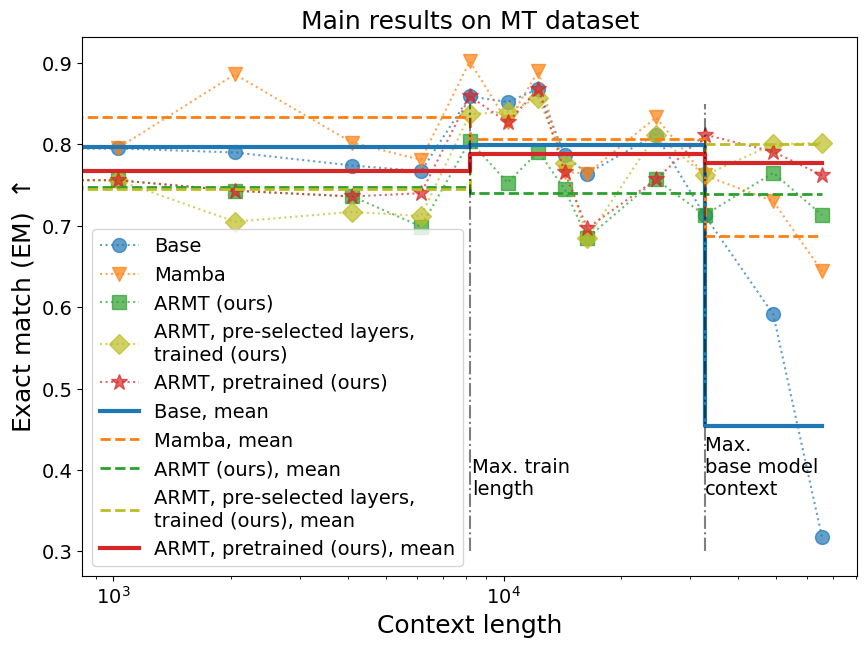

In [262]:

model_keys = [
    "Gemma-3-1B-IT, MT, 8k",
    "Mamba-2-1.3B best, MT, 8k",#"Mamba-1.3B gen64, MT, 8k",
    "ARMT-Gemma-3-1B-IT, MT, 8k",
    #"ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers used",
    #"ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers trained",
    "ARMT-Gemma-3-1B-IT, MT, 8k, top-5 layers trained",
    #"ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained-prelim-v3",
    "ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained-final",
]
model_names = [
    "Base",
    "Mamba",
    "ARMT (ours)",
    #"ARMT, top-4 layers",
    #"ARMT, top-4 layers, trained",
    "ARMT, pre-selected layers, \ntrained (ours)",
    "ARMT, pretrained (ours)",
]
fig = plt.figure(figsize=(10,7))
cmap=mpl.colormaps["tab10"].colors
color_idx = [0,1,2, 8, 3]
x = np.array([0, 1, 2, 4, 6, 8, 10, 12, 14, 16, 24, 32, 48, 64]) * 1024
main_ids = [0, 4]

markers = ["o", "v", "s", "D", "*"]
for idx, (key, name) in enumerate(zip(model_keys, model_names)):
    ms = 10 if markers[idx] != "*" else 12
    plt.plot(x, list(buf_res[key])[:1] + list(buf_res[key])[:len(x)-1], marker = markers[idx], ms=ms, alpha=0.7, linestyle=":",
             label=name, color=cmap[color_idx[idx]])
global_fs = 18
cmap=mpl.colormaps["tab10"].colors
new_x = np.array([0, 8, 8, 32, 32, 64]) * 1024
new_y_ids = [[0, 5], [0, 5], [5, 11], [5, 11], [11,13], [11,13]]
for idx, (key, name) in enumerate(zip(model_keys, model_names)):
    linewidth = 3 if idx in main_ids else 2
    linestyle = "-" if idx in main_ids else "--"
    new_y = [np.mean(np.array(list(buf_res[key]))[new_y_idx[0]:new_y_idx[-1]]) for new_y_idx in new_y_ids]
    #print(np.array(list(buf_res[key]))[new_y_ids[0][0]:new_y_ids[0][-1]])
    #print(key, new_y)
    plt.plot(new_x, new_y, label=name+", mean", alpha=1., color=cmap[color_idx[idx]], linestyle=linestyle, linewidth=linewidth)
#plt.plot(x, list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k"])[:1] + list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k"])[:len(x)-1], label="ARMT, 8k")
#plt.plot(x, list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain), prelim"])[:1] + list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain), prelim"])[:len(x)-1], label="ARMT, 8k, pretrained")

plt.vlines([32*1024], ymin=0.3, ymax=0.85, linestyle="-.", color="k", alpha=0.5)
plt.vlines([8*1024], ymin=0.3, ymax=0.85, linestyle="-.", color="k", alpha=0.5)
idx = 0
shift = [-100, -100, ]
train_sizes = [8*1024, 32*1024]
dnames = ["Max. train \nlength", "Max. \nbase model \ncontext"]
idx = 0
for x, y, text in zip(train_sizes, [0.38] * len(train_sizes), dnames):
    plt.text(x-shift[idx], y-0.01, text, fontsize=14)
    idx += 1
plt.xscale('log') 
plt.xlabel("Context length", fontsize=global_fs)
plt.ylabel("Exact match (EM) $\\uparrow$", fontsize=global_fs)
plt.title("Main results on MT dataset", fontsize=global_fs)
plt.legend(fontsize=14)
plt.tick_params(axis='both', which='major', labelsize=14)
plt.show()
fig.tight_layout()
fig.savefig("../../paper_results/main_res_mt_gemma_new_mamba.pdf")

### Best MT res, with pretrain

In [78]:
#buf_res = buf_res.loc[[26, 24,15,19, 22, ]]
#buf_res = buf_res.loc[[26, 24, 15,19, 22, 83,84, 126,124 ]]
#buf_res = buf_res.loc[[ 24, 15,19, 22, 83,84, 127, 128, 129]]
#buf_res = buf_res.loc[[ 24, 15,19, 22, 83,84, 128]]
buf_res = buf_res.loc[[ 24, 15,18, 22, 83,84, 128]]

buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [79]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 2k","ARMT-Gemma-3-1B-IT, MT, 4k","ARMT-Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 2k, from pretrained","ARMT-Gemma-3-1B-IT, MT, 4k, from pretrained","ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained-final"
0k_1k,0.795,0.782,0.782,0.756,0.769,0.756,0.756
1k_2k,0.790,0.724,0.705,0.743,0.752,0.743,0.743
2k_4k,0.774,0.689,0.698,0.736,0.708,0.708,0.736
4k_6k,0.767,0.616,0.630,0.699,0.671,0.671,0.740
6k_8k,0.859,0.609,0.641,0.804,0.793,0.804,0.859
8k_10k,0.852,0.506,0.630,0.753,0.753,0.790,0.827
10k_12k,0.868,0.374,0.549,0.791,0.692,0.747,0.868
12k_14k,0.787,0.404,0.500,0.745,0.745,0.734,0.766
14k_16k,0.764,0.337,0.551,0.685,0.629,0.640,0.697
16k_24k,0.812,0.229,0.486,0.757,0.632,0.639,0.757


In [80]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-"))

\begin{tabular}{lccccccc}
\toprule
Model & Gemma-3-1B-IT, MT, 8k & ARMT-Gemma-3-1B-IT, MT, 2k & ARMT-Gemma-3-1B-IT, MT, 4k & ARMT-Gemma-3-1B-IT, MT, 8k & ARMT-Gemma-3-1B-IT, MT, 2k, from pretrained & ARMT-Gemma-3-1B-IT, MT, 4k, from pretrained & ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained-final \\
\midrule
0k-1k & {\cellcolor[HTML]{2E9700}} \color[HTML]{F1F1F1} 0.795 & {\cellcolor[HTML]{389C00}} \color[HTML]{F1F1F1} 0.782 & {\cellcolor[HTML]{389C00}} \color[HTML]{F1F1F1} 0.782 & {\cellcolor[HTML]{48A400}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{40A000}} \color[HTML]{F1F1F1} 0.769 & {\cellcolor[HTML]{48A400}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{48A400}} \color[HTML]{F1F1F1} 0.756 \\
1k-2k & {\cellcolor[HTML]{329900}} \color[HTML]{F1F1F1} 0.790 & {\cellcolor[HTML]{5EAF00}} \color[HTML]{F1F1F1} 0.724 & {\cellcolor[HTML]{6AB500}} \color[HTML]{F1F1F1} 0.705 & {\cellcolor[HTML]{52A900}} \color[HTML]{F1F1F1} 0.743 & {\cellcolor[HTML]{4CA600}} \color[HTML]{F1F1F1} 0.752 & {\c

### Best MT res, main res

In [110]:
#buf_res = buf_res.loc[[26, 24,15,19, 22, ]]
#buf_res = buf_res.loc[[26, 24, 15,19, 22, 83,84, 126,124 ]]
#buf_res = buf_res.loc[[26, 24, 22, 70, 127 ]]
buf_res = buf_res.loc[[26, 24, 22, 70, 128 ]]

buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [111]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, instructive prompt","Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 8k, top-5 layers trained","ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained-final"
0k_1k,0.000,0.795,0.756,0.756,0.756
1k_2k,0.000,0.790,0.743,0.705,0.743
2k_4k,0.000,0.774,0.736,0.717,0.736
4k_6k,0.000,0.767,0.699,0.712,0.740
6k_8k,0.000,0.859,0.804,0.837,0.859
8k_10k,0.000,0.852,0.753,0.840,0.827
10k_12k,0.011,0.868,0.791,0.857,0.868
12k_14k,0.000,0.787,0.745,0.777,0.766
14k_16k,0.000,0.764,0.685,0.685,0.697
16k_24k,0.000,0.812,0.757,0.812,0.757


In [112]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-"))

\begin{tabular}{lccccc}
\toprule
Model & Gemma-3-1B-IT, instructive prompt & Gemma-3-1B-IT, MT, 8k & ARMT-Gemma-3-1B-IT, MT, 8k & ARMT-Gemma-3-1B-IT, MT, 8k, top-5 layers trained & ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained-final \\
\midrule
0k-1k & {\cellcolor[HTML]{FF0000}} \color[HTML]{F1F1F1} 0.000 & {\cellcolor[HTML]{2A9500}} \color[HTML]{F1F1F1} 0.795 & {\cellcolor[HTML]{42A100}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{42A100}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{42A100}} \color[HTML]{F1F1F1} 0.756 \\
1k-2k & {\cellcolor[HTML]{FF0000}} \color[HTML]{F1F1F1} 0.000 & {\cellcolor[HTML]{2E9700}} \color[HTML]{F1F1F1} 0.790 & {\cellcolor[HTML]{48A400}} \color[HTML]{F1F1F1} 0.743 & {\cellcolor[HTML]{60B000}} \color[HTML]{F1F1F1} 0.705 & {\cellcolor[HTML]{48A400}} \color[HTML]{F1F1F1} 0.743 \\
2k-4k & {\cellcolor[HTML]{FF0000}} \color[HTML]{F1F1F1} 0.000 & {\cellcolor[HTML]{369B00}} \color[HTML]{F1F1F1} 0.774 & {\cellcolor[HTML]{4CA600}} \color[HTML]{F1F1F1} 0.736 & {\c

### Best MT res, SmolLM

In [408]:
#buf_res = buf_res.loc[[26, 24,15,19, 22, ]]
buf_res = buf_res.loc[[80, 82, 74,75,76 ]]

buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [409]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"SmolLM-2-360M-IT, base prompt","SmolLM-2-360M-IT, MT, 8k","ARMT-SmolLM-2-360M-IT, MT, 2k","ARMT-SmolLM-2-360M-IT, MT, 4k","ARMT-SmolLM-2-360M-IT, MT, 8k"
0k_1k,0.000,0.795,0.718,0.756,0.769
1k_2k,0.000,0.790,0.638,0.686,0.705
2k_4k,0.000,0.736,0.642,0.717,0.698
4k_6k,0.000,0.685,0.603,0.630,0.630
6k_8k,0.000,0.837,0.598,0.739,0.761
8k_10k,0.000,0.568,0.469,0.802,0.815
10k_12k,0.011,0.000,0.418,0.692,0.747
12k_14k,0.000,0.000,0.138,0.755,0.755
14k_16k,0.000,0.000,0.000,0.663,0.629
16k_24k,0.000,0.000,0.014,0.708,0.715


In [410]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-"))

\begin{tabular}{lccccc}
\toprule
Model & SmolLM-2-360M-IT, base prompt & SmolLM-2-360M-IT, MT, 8k & ARMT-SmolLM-2-360M-IT, MT, 2k & ARMT-SmolLM-2-360M-IT, MT, 4k & ARMT-SmolLM-2-360M-IT, MT, 8k \\
\midrule
0k-1k & {\cellcolor[HTML]{FF0000}} \color[HTML]{F1F1F1} 0.000 & {\cellcolor[HTML]{188C00}} \color[HTML]{F1F1F1} 0.795 & {\cellcolor[HTML]{48A400}} \color[HTML]{F1F1F1} 0.718 & {\cellcolor[HTML]{309800}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{289400}} \color[HTML]{F1F1F1} 0.769 \\
1k-2k & {\cellcolor[HTML]{FF0000}} \color[HTML]{F1F1F1} 0.000 & {\cellcolor[HTML]{1C8E00}} \color[HTML]{F1F1F1} 0.790 & {\cellcolor[HTML]{78BC00}} \color[HTML]{F1F1F1} 0.638 & {\cellcolor[HTML]{5CAE00}} \color[HTML]{F1F1F1} 0.686 & {\cellcolor[HTML]{50A800}} \color[HTML]{F1F1F1} 0.705 \\
2k-4k & {\cellcolor[HTML]{FF0000}} \color[HTML]{F1F1F1} 0.000 & {\cellcolor[HTML]{3C9E00}} \color[HTML]{F1F1F1} 0.736 & {\cellcolor[HTML]{76BB00}} \color[HTML]{F1F1F1} 0.642 & {\cellcolor[HTML]{48A400}} \color[HTML]{

### Main MT res for plot, SmolLM

In [654]:
#buf_res = buf_res.loc[[26, 24,15,19, 22, ]]
buf_res = buf_res.loc[[80, 82, 74,75,76, 77,78,79 ]]


buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [655]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"SmolLM-2-360M-IT, base prompt","SmolLM-2-360M-IT, MT, 8k","ARMT-SmolLM-2-360M-IT, MT, 2k","ARMT-SmolLM-2-360M-IT, MT, 4k","ARMT-SmolLM-2-360M-IT, MT, 8k","ARMT-SmolLM-2-360M-IT, MT, 2k, top-6 layers trained","ARMT-SmolLM-2-360M-IT, MT, 4k, top-6 layers trained","ARMT-SmolLM-2-360M-IT, MT, 8k, top-6 layers trained"
0k_1k,0.000,0.795,0.718,0.756,0.769,0.731,0.744,0.744
1k_2k,0.000,0.790,0.638,0.686,0.705,0.648,0.667,0.667
2k_4k,0.000,0.736,0.642,0.717,0.698,0.642,0.698,0.698
4k_6k,0.000,0.685,0.603,0.630,0.630,0.562,0.658,0.644
6k_8k,0.000,0.837,0.598,0.739,0.761,0.543,0.728,0.728
8k_10k,0.000,0.568,0.469,0.802,0.815,0.469,0.704,0.765
10k_12k,0.011,0.000,0.418,0.692,0.747,0.429,0.692,0.758
12k_14k,0.000,0.000,0.138,0.755,0.755,0.372,0.702,0.734
14k_16k,0.000,0.000,0.000,0.663,0.629,0.202,0.629,0.640
16k_24k,0.000,0.000,0.014,0.708,0.715,0.146,0.625,0.653


In [656]:
import matplotlib.pyplot as plt
import matplotlib as mpl


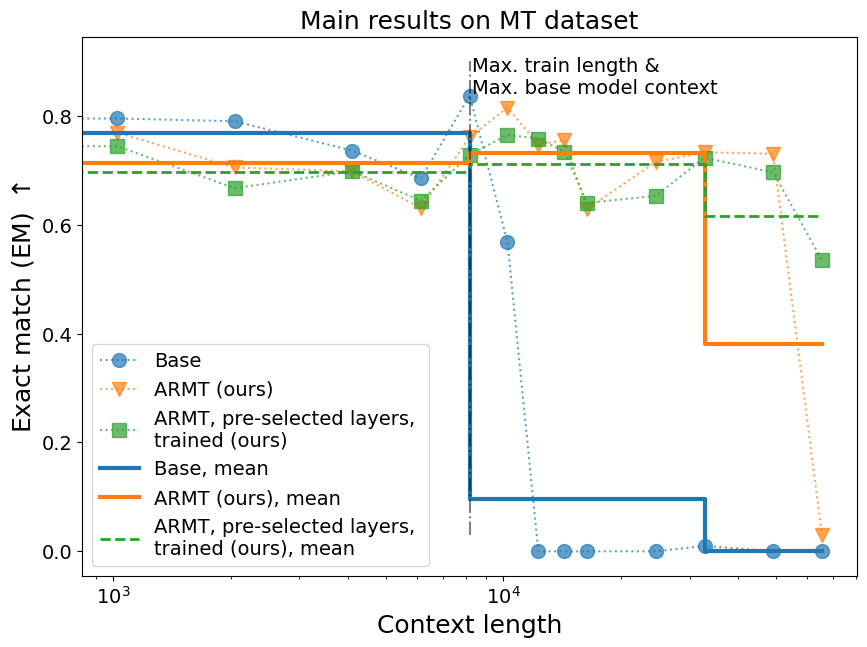

In [657]:

model_keys = [
    "SmolLM-2-360M-IT, MT, 8k",
    #"Mamba-1.3B gen64, MT, 8k",
    "ARMT-SmolLM-2-360M-IT, MT, 8k",
    #"ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers used",
    #"ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers trained",
    "ARMT-SmolLM-2-360M-IT, MT, 8k, top-6 layers trained",
    #"ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained-prelim-v2",
]
model_names = [
    "Base",
    #"Mamba",
    "ARMT (ours)",
    #"ARMT, top-4 layers",
    #"ARMT, top-4 layers, trained",
    "ARMT, pre-selected layers, \ntrained (ours)",
    #"ARMT, pretrained",
]
fig = plt.figure(figsize=(10,7))
cmap=mpl.colormaps["tab10"].colors
color_idx = [0,1,2, 8, 3]
main_ids = [0, 1]
x = np.array([0, 1, 2, 4, 6, 8, 10, 12, 14, 16, 24, 32, 48, 64]) * 1024

markers = ["o", "v", "s", "*"]
for idx, (key, name) in enumerate(zip(model_keys, model_names)):
    ms = 10 if markers[idx] != "*" else 12
    plt.plot(x, list(buf_res[key])[:1] + list(buf_res[key])[:len(x)-1], marker = markers[idx], ms=ms, alpha=0.7, linestyle=":",
             label=name, color=cmap[color_idx[idx]])
global_fs = 18
cmap=mpl.colormaps["tab10"].colors
new_x = np.array([0, 8, 8, 32, 32, 64]) * 1024
new_y_ids = [[0, 5], [0, 5], [5, 11], [5, 11], [11,13], [11,13]]
for idx, (key, name) in enumerate(zip(model_keys, model_names)):
    linewidth = 3 if idx in main_ids else 2
    linestyle = "-" if idx in main_ids else "--"
    new_y = [np.mean(np.array(list(buf_res[key]))[new_y_idx[0]:new_y_idx[-1]]) for new_y_idx in new_y_ids]
    #print(np.array(list(buf_res[key]))[new_y_ids[0][0]:new_y_ids[0][-1]])
    #print(key, new_y)
    plt.plot(new_x, new_y, label=name+", mean", alpha=1., color=cmap[color_idx[idx]], linestyle=linestyle, linewidth=linewidth)
#plt.plot(x, list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k"])[:1] + list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k"])[:len(x)-1], label="ARMT, 8k")
#plt.plot(x, list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain), prelim"])[:1] + list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain), prelim"])[:len(x)-1], label="ARMT, 8k, pretrained")

plt.vlines([8*1024], ymin=0.03, ymax=0.9, linestyle="-.", color="k", alpha=0.5)
idx = 0
shift = [-100, -100, ]
train_sizes = [8*1024]#, 32*1024]
dnames = ["Max. train length & \nMax. base model context"]
idx = 0
for x, y, text in zip(train_sizes, [0.85] * len(train_sizes), dnames):
    plt.text(x-shift[idx], y-0.01, text, fontsize=14)
    idx += 1
plt.xscale('log') 
plt.xlabel("Context length", fontsize=global_fs)
plt.ylabel("Exact match (EM) $\\uparrow$", fontsize=global_fs)
plt.title("Main results on MT dataset", fontsize=global_fs)
plt.legend(fontsize=14)
plt.tick_params(axis='both', which='major', labelsize=14)
plt.show()
fig.tight_layout()
fig.savefig("../../paper_results/main_res_mt_smollm.pdf")

### Best MT res, block ablations, SmolLM

In [529]:
#buf_res = buf_res.loc[[26, 24,15,19, 22, ]]
buf_res = buf_res.loc[[82,76, 86,87,88,89, 125,122]]

buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [530]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"SmolLM-2-360M-IT, MT, 8k","ARMT-SmolLM-2-360M-IT, MT, 8k","ARMT-SmolLM-2-360M-IT, MT, 8k, 0-7 layers removed","ARMT-SmolLM-2-360M-IT, MT, 8k, 8-15 layers removed","ARMT-SmolLM-2-360M-IT, MT, 8k, 16-23 layers removed","ARMT-SmolLM-2-360M-IT, MT, 8k, 24-31 layers removed","ARMT-SmolLM-2-360M-IT, MT, 8k, top-1 layer used","ARMT-SmolLM-2-360M-IT, MT, 8k, top-4 layers used"
0k_1k,0.795,0.769,0.769,0.769,0.756,0.756,0.756,0.756
1k_2k,0.790,0.705,0.695,0.695,0.438,0.619,0.571,0.638
2k_4k,0.736,0.698,0.708,0.698,0.387,0.651,0.613,0.623
4k_6k,0.685,0.630,0.671,0.658,0.342,0.616,0.548,0.658
6k_8k,0.837,0.761,0.717,0.761,0.315,0.750,0.598,0.750
8k_10k,0.568,0.815,0.790,0.778,0.321,0.716,0.519,0.691
10k_12k,0.000,0.747,0.736,0.769,0.374,0.714,0.462,0.725
12k_14k,0.000,0.755,0.755,0.713,0.255,0.734,0.479,0.723
14k_16k,0.000,0.629,0.618,0.652,0.292,0.573,0.360,0.562
16k_24k,0.000,0.715,0.715,0.701,0.243,0.653,0.479,0.653


In [531]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-"))

\begin{tabular}{lcccccccc}
\toprule
Model & SmolLM-2-360M-IT, MT, 8k & ARMT-SmolLM-2-360M-IT, MT, 8k & ARMT-SmolLM-2-360M-IT, MT, 8k, 0-7 layers removed & ARMT-SmolLM-2-360M-IT, MT, 8k, 8-15 layers removed & ARMT-SmolLM-2-360M-IT, MT, 8k, 16-23 layers removed & ARMT-SmolLM-2-360M-IT, MT, 8k, 24-31 layers removed & ARMT-SmolLM-2-360M-IT, MT, 8k, top-1 layer used & ARMT-SmolLM-2-360M-IT, MT, 8k, top-4 layers used \\
\midrule
0k-1k & {\cellcolor[HTML]{188C00}} \color[HTML]{F1F1F1} 0.795 & {\cellcolor[HTML]{289400}} \color[HTML]{F1F1F1} 0.769 & {\cellcolor[HTML]{289400}} \color[HTML]{F1F1F1} 0.769 & {\cellcolor[HTML]{289400}} \color[HTML]{F1F1F1} 0.769 & {\cellcolor[HTML]{309800}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{309800}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{309800}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{309800}} \color[HTML]{F1F1F1} 0.756 \\
1k-2k & {\cellcolor[HTML]{1C8E00}} \color[HTML]{F1F1F1} 0.790 & {\cellcolor[HTML]{50A800}} \color[HTML]{F1F1F1} 0.70

### Best MT res, SmolLM, pre-selected

In [543]:
#buf_res = buf_res.loc[[26, 24,15,19, 22, ]]
buf_res = buf_res.loc[[ 82, 74,75,76, 77,78,79 ]]

buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [544]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"SmolLM-2-360M-IT, MT, 8k","ARMT-SmolLM-2-360M-IT, MT, 2k","ARMT-SmolLM-2-360M-IT, MT, 4k","ARMT-SmolLM-2-360M-IT, MT, 8k","ARMT-SmolLM-2-360M-IT, MT, 2k, top-6 layers trained","ARMT-SmolLM-2-360M-IT, MT, 4k, top-6 layers trained","ARMT-SmolLM-2-360M-IT, MT, 8k, top-6 layers trained"
0k_1k,0.795,0.718,0.756,0.769,0.731,0.744,0.744
1k_2k,0.790,0.638,0.686,0.705,0.648,0.667,0.667
2k_4k,0.736,0.642,0.717,0.698,0.642,0.698,0.698
4k_6k,0.685,0.603,0.630,0.630,0.562,0.658,0.644
6k_8k,0.837,0.598,0.739,0.761,0.543,0.728,0.728
8k_10k,0.568,0.469,0.802,0.815,0.469,0.704,0.765
10k_12k,0.000,0.418,0.692,0.747,0.429,0.692,0.758
12k_14k,0.000,0.138,0.755,0.755,0.372,0.702,0.734
14k_16k,0.000,0.000,0.663,0.629,0.202,0.629,0.640
16k_24k,0.000,0.014,0.708,0.715,0.146,0.625,0.653


In [545]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-"))

\begin{tabular}{lccccccc}
\toprule
Model & SmolLM-2-360M-IT, MT, 8k & ARMT-SmolLM-2-360M-IT, MT, 2k & ARMT-SmolLM-2-360M-IT, MT, 4k & ARMT-SmolLM-2-360M-IT, MT, 8k & ARMT-SmolLM-2-360M-IT, MT, 2k, top-6 layers trained & ARMT-SmolLM-2-360M-IT, MT, 4k, top-6 layers trained & ARMT-SmolLM-2-360M-IT, MT, 8k, top-6 layers trained \\
\midrule
0k-1k & {\cellcolor[HTML]{188C00}} \color[HTML]{F1F1F1} 0.795 & {\cellcolor[HTML]{48A400}} \color[HTML]{F1F1F1} 0.718 & {\cellcolor[HTML]{309800}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{289400}} \color[HTML]{F1F1F1} 0.769 & {\cellcolor[HTML]{40A000}} \color[HTML]{F1F1F1} 0.731 & {\cellcolor[HTML]{389C00}} \color[HTML]{F1F1F1} 0.744 & {\cellcolor[HTML]{389C00}} \color[HTML]{F1F1F1} 0.744 \\
1k-2k & {\cellcolor[HTML]{1C8E00}} \color[HTML]{F1F1F1} 0.790 & {\cellcolor[HTML]{78BC00}} \color[HTML]{F1F1F1} 0.638 & {\cellcolor[HTML]{5CAE00}} \color[HTML]{F1F1F1} 0.686 & {\cellcolor[HTML]{50A800}} \color[HTML]{F1F1F1} 0.705 & {\cellcolor[HTML]{72B900}} \c

### Best MT res, assoc. ablation, all layers

In [459]:
#buf_res = buf_res.loc[[24, 22, 27,28,29,30 ]]
#buf_res = buf_res.loc[[24, 22 ]+ list(range(31, 31+13))]
#buf_res = buf_res.loc[[82, 76 ]+ list(range(90, 90+32))]
#buf_res = buf_res.loc[[82, 76 ]+ list(range(90, 90+16))]
buf_res = buf_res.loc[[82, 76 ]+ list(range(90+16, 90+32))]

buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [460]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"SmolLM-2-360M-IT, MT, 8k","ARMT-SmolLM-2-360M-IT, MT, 8k","SLM,W/o layer 16","SLM,W/o layer 17","SLM,W/o layer 18","SLM,W/o layer 19","SLM,W/o layer 20","SLM,W/o layer 21","SLM,W/o layer 22","SLM,W/o layer 23","SLM,W/o layer 24","SLM,W/o layer 25","SLM,W/o layer 26","SLM,W/o layer 27","SLM,W/o layer 28","SLM,W/o layer 29","SLM,W/o layer 30","SLM,W/o layer 31"
0k_1k,0.795,0.769,0.769,0.769,0.769,0.769,0.769,0.769,0.769,0.756,0.769,0.769,0.769,0.769,0.756,0.769,0.756,0.769
1k_2k,0.790,0.705,0.705,0.705,0.705,0.705,0.705,0.705,0.705,0.448,0.667,0.714,0.705,0.667,0.686,0.657,0.686,0.695
2k_4k,0.736,0.698,0.698,0.689,0.698,0.698,0.698,0.698,0.689,0.415,0.698,0.698,0.698,0.698,0.670,0.708,0.698,0.698
4k_6k,0.685,0.630,0.644,0.658,0.658,0.644,0.658,0.644,0.630,0.370,0.616,0.644,0.630,0.658,0.658,0.658,0.630,0.630
6k_8k,0.837,0.761,0.761,0.717,0.761,0.761,0.761,0.804,0.761,0.348,0.696,0.761,0.761,0.750,0.815,0.783,0.761,0.761
8k_10k,0.568,0.815,0.815,0.741,0.802,0.802,0.815,0.802,0.802,0.296,0.753,0.815,0.815,0.802,0.815,0.802,0.815,0.802
10k_12k,0.000,0.747,0.736,0.703,0.747,0.736,0.747,0.736,0.747,0.407,0.725,0.725,0.725,0.769,0.725,0.758,0.736,0.758
12k_14k,0.000,0.755,0.755,0.755,0.755,0.755,0.755,0.755,0.755,0.298,0.745,0.745,0.766,0.755,0.734,0.766,0.766,0.745
14k_16k,0.000,0.629,0.629,0.652,0.629,0.618,0.629,0.629,0.629,0.326,0.640,0.629,0.629,0.618,0.663,0.629,0.629,0.629
16k_24k,0.000,0.715,0.715,0.681,0.722,0.708,0.708,0.708,0.715,0.236,0.681,0.715,0.722,0.722,0.715,0.708,0.729,0.715


In [461]:
# top-1 - 23
# top-4 - 23, 24, 17, 14

In [462]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-")
      .replace("In-Domain (0k-8k)", "\\begin{tabular}[c]{@{}l@{}}{In-Domain}\\\\ {(0k-8k)}\\end{tabular}")
      .replace("OOD (8k-65k)", "\\begin{tabular}[c]{@{}l@{}}{OOD}\\\\ {(8k-65k)}\\end{tabular}")
      .replace("Long-OOD (32k-65k)", "\\begin{tabular}[c]{@{}l@{}}{Long-OOD}\\\\ {(32k-65k)}\\end{tabular}")
      .replace("Full (0k-65k)", "\\begin{tabular}[c]{@{}l@{}}{Full}\\\\ {(0k-65k)}\\end{tabular}"))

\begin{tabular}{lcccccccccccccccccc}
\toprule
Model & SmolLM-2-360M-IT, MT, 8k & ARMT-SmolLM-2-360M-IT, MT, 8k & SLM,W/o layer 16 & SLM,W/o layer 17 & SLM,W/o layer 18 & SLM,W/o layer 19 & SLM,W/o layer 20 & SLM,W/o layer 21 & SLM,W/o layer 22 & SLM,W/o layer 23 & SLM,W/o layer 24 & SLM,W/o layer 25 & SLM,W/o layer 26 & SLM,W/o layer 27 & SLM,W/o layer 28 & SLM,W/o layer 29 & SLM,W/o layer 30 & SLM,W/o layer 31 \\
\midrule
0k-1k & {\cellcolor[HTML]{188C00}} \color[HTML]{F1F1F1} 0.795 & {\cellcolor[HTML]{289400}} \color[HTML]{F1F1F1} 0.769 & {\cellcolor[HTML]{289400}} \color[HTML]{F1F1F1} 0.769 & {\cellcolor[HTML]{289400}} \color[HTML]{F1F1F1} 0.769 & {\cellcolor[HTML]{289400}} \color[HTML]{F1F1F1} 0.769 & {\cellcolor[HTML]{289400}} \color[HTML]{F1F1F1} 0.769 & {\cellcolor[HTML]{289400}} \color[HTML]{F1F1F1} 0.769 & {\cellcolor[HTML]{289400}} \color[HTML]{F1F1F1} 0.769 & {\cellcolor[HTML]{289400}} \color[HTML]{F1F1F1} 0.769 & {\cellcolor[HTML]{309800}} \color[HTML]{F1F1F1} 0.756 & {\cel

### Best MT res, baselines comparison

In [431]:
#buf_res = buf_res.loc[[26, 24,15,19, 22, ]]
buf_res = buf_res.loc[[24, 22, 128, 203,196,198, 187]]

buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [432]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained-final","Mamba-1.4B best, MT, 8k","Mamba-2-1.3B best, MT, 8k","DeltaNet-1.3B best, MT, 8k","xLSTM-1.3B, MT, 8k"
0k_1k,0.795,0.756,0.756,0.846,0.795,0.769,0.769
1k_2k,0.790,0.743,0.743,0.857,0.886,0.819,0.800
2k_4k,0.774,0.736,0.736,0.802,0.802,0.726,0.755
4k_6k,0.767,0.699,0.740,0.836,0.781,0.726,0.822
6k_8k,0.859,0.804,0.859,0.902,0.902,0.891,0.870
8k_10k,0.852,0.753,0.827,0.877,0.827,0.864,0.864
10k_12k,0.868,0.791,0.868,0.879,0.890,0.846,0.890
12k_14k,0.787,0.745,0.766,0.777,0.766,0.755,0.819
14k_16k,0.764,0.685,0.697,0.764,0.764,0.708,0.742
16k_24k,0.812,0.757,0.757,0.882,0.833,0.757,0.819


In [389]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-"))

\begin{tabular}{lccccccc}
\toprule
Model & Gemma-3-1B-IT, MT, 8k & ARMT-Gemma-3-1B-IT, MT, 8k & ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained-final & Mamba-1.4B best, MT, 8k & Mamba-2-1.3B best, MT, 8k & DeltaNet-1.3B best, MT, 8k & xLSTM-1.3B, MT, 8k \\
\midrule
0k-1k & {\cellcolor[HTML]{5CAE00}} \color[HTML]{F1F1F1} 0.795 & {\cellcolor[HTML]{7EBF00}} \color[HTML]{000000} 0.756 & {\cellcolor[HTML]{7EBF00}} \color[HTML]{000000} 0.756 & {\cellcolor[HTML]{309800}} \color[HTML]{F1F1F1} 0.846 & {\cellcolor[HTML]{5CAE00}} \color[HTML]{F1F1F1} 0.795 & {\cellcolor[HTML]{74BA00}} \color[HTML]{F1F1F1} 0.769 & {\cellcolor[HTML]{74BA00}} \color[HTML]{F1F1F1} 0.769 \\
1k-2k & {\cellcolor[HTML]{62B100}} \color[HTML]{F1F1F1} 0.790 & {\cellcolor[HTML]{8AC500}} \color[HTML]{000000} 0.743 & {\cellcolor[HTML]{8AC500}} \color[HTML]{000000} 0.743 & {\cellcolor[HTML]{269300}} \color[HTML]{F1F1F1} 0.857 & {\cellcolor[HTML]{0E8700}} \color[HTML]{F1F1F1} 0.886 & {\cellcolor[HTML]{48A400}} \color[HTML]{F1F1F1} 0

### Best MT res, SmolLM

In [498]:
#buf_res = buf_res.loc[[26, 24,15,19, 22, ]]
#buf_res = buf_res.loc[[80, 82, 190,193,194,76]]
buf_res = buf_res.loc[[80, 82, 190,193,194,76]]

buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [499]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"SmolLM-2-360M-IT, base prompt","SmolLM-2-360M-IT, MT, 8k","SmolLM-2-360M-IT-YaRN, MT, 8k","SmolLM-2-360M-IT-YaRN-HF, MT, 8k","SmolLM-2-360M-IT-YaRN-HF+Adapt, MT, 8k","ARMT-SmolLM-2-360M-IT, MT, 8k"
0k_1k,0.000,0.795,0.269,0.731,0.333,0.769
1k_2k,0.000,0.790,0.267,0.657,0.257,0.705
2k_4k,0.000,0.736,0.255,0.623,0.264,0.698
4k_6k,0.000,0.685,0.137,0.671,0.301,0.630
6k_8k,0.000,0.837,0.174,0.728,0.250,0.761
8k_10k,0.000,0.568,0.136,0.407,0.272,0.815
10k_12k,0.011,0.000,0.099,0.011,0.176,0.747
12k_14k,0.000,0.000,0.096,0.000,0.106,0.755
14k_16k,0.000,0.000,0.056,0.000,0.000,0.629
16k_24k,0.000,0.000,0.028,0.000,0.000,0.715


In [323]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-")
      .replace("In-Domain (0k-8k)", "\\begin{tabular}[c]{@{}l@{}}{In-Domain}\\\\ {(0k-8k)}\\end{tabular}")
      .replace("OOD (8k-65k)", "\\begin{tabular}[c]{@{}l@{}}{OOD}\\\\ {(8k-65k)}\\end{tabular}")
      .replace("Long-OOD (32k-65k)", "\\begin{tabular}[c]{@{}l@{}}{Long-OOD}\\\\ {(32k-65k)}\\end{tabular}")
      .replace("Full (0k-65k)", "\\begin{tabular}[c]{@{}l@{}}{Full}\\\\ {(0k-65k)}\\end{tabular}"))

\begin{tabular}{lcccc}
\toprule
Model & SmolLM-2-360M-IT, base prompt & SmolLM-2-360M-IT, MT, 8k & SmolLM-2-360M-IT-YaRN, MT, 8k & ARMT-SmolLM-2-360M-IT, MT, 8k \\
\midrule
0k-1k & {\cellcolor[HTML]{FF0000}} \color[HTML]{F1F1F1} 0.000 & {\cellcolor[HTML]{188C00}} \color[HTML]{F1F1F1} 0.795 & {\cellcolor[HTML]{FFA400}} \color[HTML]{000000} 0.269 & {\cellcolor[HTML]{289400}} \color[HTML]{F1F1F1} 0.769 \\
1k-2k & {\cellcolor[HTML]{FF0000}} \color[HTML]{F1F1F1} 0.000 & {\cellcolor[HTML]{1C8E00}} \color[HTML]{F1F1F1} 0.790 & {\cellcolor[HTML]{FFA200}} \color[HTML]{000000} 0.267 & {\cellcolor[HTML]{50A800}} \color[HTML]{F1F1F1} 0.705 \\
2k-4k & {\cellcolor[HTML]{FF0000}} \color[HTML]{F1F1F1} 0.000 & {\cellcolor[HTML]{3C9E00}} \color[HTML]{F1F1F1} 0.736 & {\cellcolor[HTML]{FF9A00}} \color[HTML]{000000} 0.255 & {\cellcolor[HTML]{54AA00}} \color[HTML]{F1F1F1} 0.698 \\
4k-6k & {\cellcolor[HTML]{FF0000}} \color[HTML]{F1F1F1} 0.000 & {\cellcolor[HTML]{5CAE00}} \color[HTML]{F1F1F1} 0.685 & {\cellco

### Best MT res, with pretrain

In [443]:
#buf_res = buf_res.loc[[26, 24,15,19, 22, ]]
#buf_res = buf_res.loc[[26, 24, 15,19, 22, 83,84, 126,124 ]]
#buf_res = buf_res.loc[[ 24, 15,19, 22, 83,84, 127, 128, 129]]
buf_res = buf_res.loc[[ 24, 15,19, 22, 83,84, 128, 129,188,189,191,192]]

buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [444]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 2k","ARMT-Gemma-3-1B-IT, MT, 4k","ARMT-Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 2k, from pretrained","ARMT-Gemma-3-1B-IT, MT, 4k, from pretrained","ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained-final","ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained-no-cl-final","ARMT-Gemma-3-1B-IT, MT, 2k, from pretrained, top-5 layers trained","ARMT-Gemma-3-1B-IT, MT, 4k, from pretrained, top-5 layers trained","ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained, top-5 layers trained","ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained, top-5 layers trained, no CL"
0k_1k,0.795,0.782,0.782,0.756,0.769,0.756,0.756,0.808,0.769,0.769,0.821,0.756
1k_2k,0.790,0.724,0.714,0.743,0.752,0.743,0.743,0.771,0.638,0.648,0.686,0.648
2k_4k,0.774,0.689,0.698,0.736,0.708,0.708,0.736,0.726,0.594,0.632,0.604,0.604
4k_6k,0.767,0.616,0.644,0.699,0.671,0.671,0.740,0.726,0.534,0.589,0.630,0.562
6k_8k,0.859,0.609,0.717,0.804,0.793,0.804,0.859,0.804,0.565,0.598,0.685,0.620
8k_10k,0.852,0.506,0.753,0.753,0.753,0.790,0.827,0.852,0.580,0.568,0.704,0.617
10k_12k,0.868,0.374,0.670,0.791,0.692,0.747,0.868,0.857,0.516,0.560,0.582,0.626
12k_14k,0.787,0.404,0.702,0.745,0.745,0.734,0.766,0.766,0.489,0.457,0.500,0.415
14k_16k,0.764,0.337,0.640,0.685,0.629,0.640,0.697,0.730,0.483,0.528,0.539,0.506
16k_24k,0.812,0.229,0.646,0.757,0.632,0.639,0.757,0.799,0.444,0.458,0.583,0.618


In [105]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-"))

\begin{tabular}{lccccccc}
\toprule
Model & Gemma-3-1B-IT, MT, 8k & ARMT-Gemma-3-1B-IT, MT, 2k & ARMT-Gemma-3-1B-IT, MT, 4k & ARMT-Gemma-3-1B-IT, MT, 8k & ARMT-Gemma-3-1B-IT, MT, 2k, from pretrained & ARMT-Gemma-3-1B-IT, MT, 4k, from pretrained & ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained-final \\
\midrule
0k-1k & {\cellcolor[HTML]{2E9700}} \color[HTML]{F1F1F1} 0.795 & {\cellcolor[HTML]{389C00}} \color[HTML]{F1F1F1} 0.782 & {\cellcolor[HTML]{389C00}} \color[HTML]{F1F1F1} 0.782 & {\cellcolor[HTML]{48A400}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{40A000}} \color[HTML]{F1F1F1} 0.769 & {\cellcolor[HTML]{48A400}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{48A400}} \color[HTML]{F1F1F1} 0.756 \\
1k-2k & {\cellcolor[HTML]{329900}} \color[HTML]{F1F1F1} 0.790 & {\cellcolor[HTML]{5EAF00}} \color[HTML]{F1F1F1} 0.724 & {\cellcolor[HTML]{64B200}} \color[HTML]{F1F1F1} 0.714 & {\cellcolor[HTML]{52A900}} \color[HTML]{F1F1F1} 0.743 & {\cellcolor[HTML]{4CA600}} \color[HTML]{F1F1F1} 0.752 & {\c

## After ARR

### Best MT res, with pretrain

In [64]:
#buf_res = buf_res.loc[[26, 24,15,19, 22, ]]
#buf_res = buf_res.loc[[26, 24, 15,19, 22, 83,84, 126,124 ]]
#buf_res = buf_res.loc[[ 24, 15,19, 22, 83,84, 128, 130,131,132]]
#buf_res = buf_res.loc[[ 24, 15,19, 22, 130,131,132]]
buf_res = buf_res.loc[[ 24, 15,18, 22, 130,131,132]]

buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [65]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 2k","ARMT-Gemma-3-1B-IT, MT, 4k","ARMT-Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 2k, mem-32","ARMT-Gemma-3-1B-IT, MT, 4k, mem-32","ARMT-Gemma-3-1B-IT, MT, 8k, mem-32"
0k_1k,0.795,0.782,0.782,0.756,0.808,0.808,0.782
1k_2k,0.790,0.724,0.705,0.743,0.695,0.676,0.695
2k_4k,0.774,0.689,0.698,0.736,0.642,0.670,0.708
4k_6k,0.767,0.616,0.630,0.699,0.603,0.644,0.699
6k_8k,0.859,0.609,0.641,0.804,0.326,0.728,0.804
8k_10k,0.852,0.506,0.630,0.753,0.123,0.654,0.840
10k_12k,0.868,0.374,0.549,0.791,0.165,0.725,0.824
12k_14k,0.787,0.404,0.500,0.745,0.096,0.649,0.723
14k_16k,0.764,0.337,0.551,0.685,0.045,0.618,0.685
16k_24k,0.812,0.229,0.486,0.757,0.062,0.583,0.722


In [66]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-")
      .replace("In-Domain (0k-8k)", "\\begin{tabular}[c]{@{}l@{}}{In-Domain}\\\\ {(0k-8k)}\\end{tabular}")
      .replace("OOD (8k-65k)", "\\begin{tabular}[c]{@{}l@{}}{OOD}\\\\ {(8k-65k)}\\end{tabular}")
      .replace("Long-OOD (32k-65k)", "\\begin{tabular}[c]{@{}l@{}}{Long-OOD}\\\\ {(32k-65k)}\\end{tabular}")
      .replace("Full (0k-65k)", "\\begin{tabular}[c]{@{}l@{}}{Full}\\\\ {(0k-65k)}\\end{tabular}"))

\begin{tabular}{lccccccc}
\toprule
Model & Gemma-3-1B-IT, MT, 8k & ARMT-Gemma-3-1B-IT, MT, 2k & ARMT-Gemma-3-1B-IT, MT, 4k & ARMT-Gemma-3-1B-IT, MT, 8k & ARMT-Gemma-3-1B-IT, MT, 2k, mem-32 & ARMT-Gemma-3-1B-IT, MT, 4k, mem-32 & ARMT-Gemma-3-1B-IT, MT, 8k, mem-32 \\
\midrule
0k-1k & {\cellcolor[HTML]{2A9500}} \color[HTML]{F1F1F1} 0.795 & {\cellcolor[HTML]{329900}} \color[HTML]{F1F1F1} 0.782 & {\cellcolor[HTML]{329900}} \color[HTML]{F1F1F1} 0.782 & {\cellcolor[HTML]{42A100}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{229100}} \color[HTML]{F1F1F1} 0.808 & {\cellcolor[HTML]{229100}} \color[HTML]{F1F1F1} 0.808 & {\cellcolor[HTML]{329900}} \color[HTML]{F1F1F1} 0.782 \\
1k-2k & {\cellcolor[HTML]{2E9700}} \color[HTML]{F1F1F1} 0.790 & {\cellcolor[HTML]{54AA00}} \color[HTML]{F1F1F1} 0.724 & {\cellcolor[HTML]{60B000}} \color[HTML]{F1F1F1} 0.705 & {\cellcolor[HTML]{4AA500}} \color[HTML]{F1F1F1} 0.743 & {\cellcolor[HTML]{66B300}} \color[HTML]{F1F1F1} 0.695 & {\cellcolor[HTML]{72B900}} \color[HT

### Best MT res, assoc. ablation, all layers, after pt

In [48]:
#buf_res = buf_res.loc[[24, 22, 27,28,29,30 ]]
#buf_res = buf_res.loc[[24, 22 ]+ list(range(31, 31+13))]
buf_res = buf_res.loc[[24, 128 ]+ list(range(133, 133+26))]
buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [49]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained-final","PT, W/o layer 0","PT, W/o layer 1","PT, W/o layer 2","PT, W/o layer 3","PT, W/o layer 4","PT, W/o layer 5","PT, W/o layer 6","PT, W/o layer 7","PT, W/o layer 8","PT, W/o layer 9","PT, W/o layer 10","PT, W/o layer 11","PT, W/o layer 12","PT, W/o layer 13","PT, W/o layer 14","PT, W/o layer 15","PT, W/o layer 16","PT, W/o layer 17","PT, W/o layer 18","PT, W/o layer 19","PT, W/o layer 20","PT, W/o layer 21","PT, W/o layer 22","PT, W/o layer 23","PT, W/o layer 24","PT, W/o layer 25"
0k_1k,0.795,0.756,0.756,0.756,0.756,0.756,0.756,0.756,0.756,0.756,0.756,0.756,0.756,0.756,0.756,0.756,0.756,0.756,0.756,0.756,0.756,0.756,0.756,0.756,0.756,0.756,0.756,0.756
1k_2k,0.790,0.743,0.743,0.743,0.743,0.743,0.743,0.743,0.743,0.743,0.743,0.743,0.743,0.648,0.743,0.743,0.743,0.743,0.743,0.743,0.714,0.743,0.771,0.743,0.743,0.752,0.743,0.752
2k_4k,0.774,0.736,0.755,0.745,0.745,0.745,0.745,0.745,0.736,0.745,0.745,0.736,0.745,0.453,0.726,0.736,0.736,0.736,0.745,0.745,0.726,0.736,0.745,0.745,0.745,0.736,0.726,0.736
4k_6k,0.767,0.740,0.712,0.740,0.740,0.740,0.740,0.740,0.740,0.740,0.740,0.740,0.740,0.411,0.726,0.740,0.740,0.740,0.740,0.740,0.726,0.740,0.740,0.740,0.740,0.753,0.740,0.726
6k_8k,0.859,0.859,0.815,0.848,0.848,0.859,0.859,0.848,0.859,0.848,0.837,0.859,0.848,0.315,0.826,0.859,0.859,0.859,0.848,0.848,0.815,0.859,0.837,0.859,0.859,0.848,0.859,0.859
8k_10k,0.852,0.827,0.852,0.827,0.827,0.827,0.827,0.827,0.827,0.827,0.827,0.827,0.827,0.407,0.827,0.827,0.827,0.827,0.827,0.827,0.790,0.827,0.852,0.827,0.827,0.840,0.815,0.827
10k_12k,0.868,0.868,0.846,0.868,0.868,0.868,0.868,0.868,0.868,0.868,0.857,0.868,0.868,0.374,0.857,0.868,0.868,0.868,0.868,0.879,0.857,0.868,0.868,0.868,0.868,0.857,0.868,0.868
12k_14k,0.787,0.766,0.787,0.766,0.777,0.755,0.755,0.766,0.766,0.755,0.755,0.766,0.755,0.362,0.798,0.766,0.766,0.766,0.766,0.755,0.755,0.766,0.777,0.755,0.766,0.777,0.755,0.755
14k_16k,0.764,0.697,0.697,0.697,0.697,0.697,0.697,0.697,0.697,0.697,0.708,0.697,0.697,0.326,0.697,0.697,0.697,0.697,0.697,0.697,0.685,0.697,0.708,0.685,0.697,0.697,0.697,0.708
16k_24k,0.812,0.757,0.764,0.750,0.757,0.757,0.764,0.757,0.757,0.736,0.750,0.757,0.757,0.306,0.750,0.757,0.757,0.757,0.750,0.750,0.729,0.757,0.778,0.750,0.757,0.722,0.757,0.757


### Best MT res, assoc. ablation, all layers, mem 32

In [54]:
#buf_res = buf_res.loc[[24, 22, 27,28,29,30 ]]
#buf_res = buf_res.loc[[24, 22 ]+ list(range(31, 31+13))]
buf_res = buf_res.loc[[24, 132 ]+ list(range(159, 159+26))]
buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [55]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 8k, mem-32","32, W/o layer 0","32, W/o layer 1","32, W/o layer 2","32, W/o layer 3","32, W/o layer 4","32, W/o layer 5","32, W/o layer 6","32, W/o layer 7","32, W/o layer 8","32, W/o layer 9","32, W/o layer 10","32, W/o layer 11","32, W/o layer 12","32, W/o layer 13","32, W/o layer 14","32, W/o layer 15","32, W/o layer 16","32, W/o layer 17","32, W/o layer 18","32, W/o layer 19","32, W/o layer 20","32, W/o layer 21","32, W/o layer 22","32, W/o layer 23","32, W/o layer 24","32, W/o layer 25"
0k_1k,0.795,0.782,0.782,0.782,0.782,0.782,0.782,0.782,0.782,0.782,0.782,0.782,0.782,0.782,0.782,0.782,0.782,0.782,0.782,0.782,0.782,0.782,0.782,0.782,0.782,0.782,0.782,0.782
1k_2k,0.790,0.695,0.695,0.695,0.695,0.695,0.695,0.695,0.695,0.695,0.695,0.695,0.695,0.695,0.695,0.695,0.590,0.695,0.695,0.695,0.648,0.714,0.695,0.705,0.695,0.695,0.695,0.705
2k_4k,0.774,0.708,0.708,0.708,0.708,0.708,0.708,0.708,0.708,0.708,0.708,0.698,0.708,0.708,0.708,0.708,0.434,0.708,0.708,0.708,0.670,0.698,0.708,0.708,0.708,0.708,0.708,0.698
4k_6k,0.767,0.699,0.699,0.699,0.699,0.699,0.699,0.699,0.699,0.699,0.699,0.699,0.699,0.699,0.699,0.699,0.397,0.699,0.699,0.699,0.685,0.699,0.699,0.699,0.699,0.658,0.699,0.685
6k_8k,0.859,0.804,0.815,0.804,0.815,0.804,0.804,0.804,0.804,0.815,0.804,0.783,0.804,0.804,0.804,0.793,0.359,0.804,0.804,0.804,0.739,0.804,0.804,0.793,0.804,0.793,0.815,0.804
8k_10k,0.852,0.840,0.840,0.840,0.827,0.840,0.840,0.840,0.840,0.840,0.840,0.815,0.840,0.840,0.840,0.840,0.407,0.840,0.840,0.840,0.765,0.827,0.840,0.827,0.840,0.852,0.840,0.827
10k_12k,0.868,0.824,0.824,0.835,0.835,0.813,0.824,0.813,0.824,0.824,0.835,0.835,0.835,0.824,0.824,0.824,0.429,0.824,0.824,0.824,0.747,0.813,0.824,0.824,0.824,0.802,0.835,0.824
12k_14k,0.787,0.723,0.723,0.723,0.734,0.723,0.723,0.723,0.723,0.723,0.734,0.745,0.723,0.723,0.723,0.734,0.234,0.723,0.723,0.723,0.713,0.723,0.723,0.723,0.723,0.702,0.723,0.723
14k_16k,0.764,0.685,0.685,0.685,0.685,0.685,0.685,0.685,0.685,0.685,0.674,0.674,0.685,0.685,0.685,0.685,0.393,0.685,0.685,0.685,0.640,0.685,0.685,0.685,0.685,0.685,0.685,0.685
16k_24k,0.812,0.722,0.722,0.722,0.729,0.722,0.715,0.715,0.722,0.715,0.708,0.715,0.722,0.722,0.722,0.708,0.264,0.722,0.722,0.722,0.681,0.715,0.722,0.729,0.722,0.694,0.722,0.729


## Figures for ICLR poster

### Main MT res for plot

In [66]:
#buf_res = buf_res.loc[[26, 24,15,19, 22, ]]
buf_res = buf_res.loc[[26, 24, 71,72,73 ,15,19, 22, 60,67,70, 85, 127, 59]]

buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [67]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, instructive prompt","Gemma-3-1B-IT, MT, 8k",Mamba-1.3B base,"Mamba-1.3B gen16, MT, 8k","Mamba-1.3B gen64, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 2k","ARMT-Gemma-3-1B-IT, MT, 4k","ARMT-Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers used","ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers trained","ARMT-Gemma-3-1B-IT, MT, 8k, top-5 layers trained","ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained-prelim","ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained-prelim-v3","ARMT-Gemma-3-1B-IT, MT, 8k, 14th layer used"
0k_1k,0.000,0.795,0.000,0.603,0.679,0.782,0.782,0.756,0.756,0.756,0.756,0.782,0.782,0.756
1k_2k,0.000,0.790,0.000,0.581,0.705,0.724,0.714,0.743,0.724,0.714,0.705,0.733,0.733,0.590
2k_4k,0.000,0.774,0.000,0.594,0.642,0.689,0.698,0.736,0.708,0.736,0.717,0.689,0.708,0.594
4k_6k,0.000,0.767,0.000,0.630,0.575,0.616,0.644,0.699,0.712,0.699,0.712,0.685,0.699,0.521
6k_8k,0.000,0.859,0.000,0.696,0.815,0.609,0.717,0.804,0.793,0.815,0.837,0.793,0.870,0.598
8k_10k,0.000,0.852,0.000,0.728,0.728,0.506,0.753,0.753,0.765,0.827,0.840,0.778,0.827,0.531
10k_12k,0.011,0.868,0.000,0.725,0.769,0.374,0.670,0.791,0.758,0.802,0.857,0.813,0.835,0.505
12k_14k,0.000,0.787,0.000,0.660,0.691,0.404,0.702,0.745,0.755,0.777,0.777,0.809,0.798,0.457
14k_16k,0.000,0.764,0.000,0.607,0.663,0.337,0.640,0.685,0.663,0.708,0.685,0.674,0.708,0.472
16k_24k,0.000,0.812,0.000,0.722,0.708,0.229,0.646,0.757,0.729,0.757,0.812,0.688,0.722,0.458


In [69]:
import matplotlib.pyplot as plt
import matplotlib as mpl


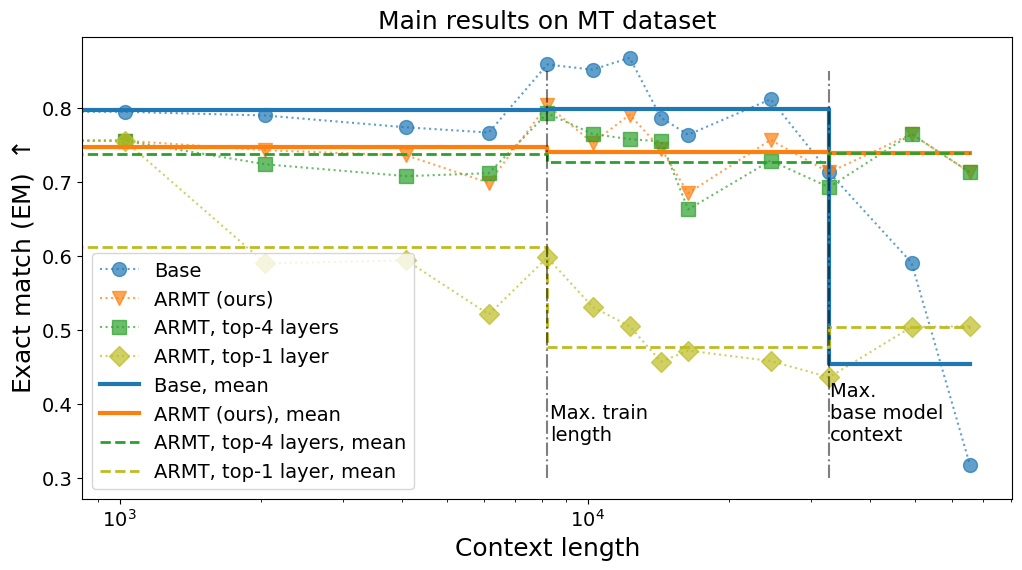

In [71]:

model_keys = [
    "Gemma-3-1B-IT, MT, 8k",
    #"Mamba-1.3B gen64, MT, 8k",
    "ARMT-Gemma-3-1B-IT, MT, 8k",
    "ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers used",
    "ARMT-Gemma-3-1B-IT, MT, 8k, 14th layer used",
    #"ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers trained",
    #"ARMT-Gemma-3-1B-IT, MT, 8k, top-5 layers trained",
    #"ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained-prelim-v3",
]
model_names = [
    "Base",
    #"Mamba",
    "ARMT (ours)",
    "ARMT, top-4 layers",
    "ARMT, top-1 layer",
    #"ARMT, top-4 layers, trained",
    #"ARMT, pre-selected layers, \ntrained (ours)",
    #"ARMT, pretrained (ours)",
]
fig = plt.figure(figsize=(12,6))
cmap=mpl.colormaps["tab10"].colors
color_idx = [0,1,2, 8, 3]
x = np.array([0, 1, 2, 4, 6, 8, 10, 12, 14, 16, 24, 32, 48, 64]) * 1024
main_ids = [0, 1]

markers = ["o", "v", "s", "D", "*"]
for idx, (key, name) in enumerate(zip(model_keys, model_names)):
    ms = 10 if markers[idx] != "*" else 12
    plt.plot(x, list(buf_res[key])[:1] + list(buf_res[key])[:len(x)-1], marker = markers[idx], ms=ms, alpha=0.7, linestyle=":",
             label=name, color=cmap[color_idx[idx]])
global_fs = 18
cmap=mpl.colormaps["tab10"].colors
new_x = np.array([0, 8, 8, 32, 32, 64]) * 1024
new_y_ids = [[0, 5], [0, 5], [5, 11], [5, 11], [11,13], [11,13]]
for idx, (key, name) in enumerate(zip(model_keys, model_names)):
    linewidth = 3 if idx in main_ids else 2
    linestyle = "-" if idx in main_ids else "--"
    new_y = [np.mean(np.array(list(buf_res[key]))[new_y_idx[0]:new_y_idx[-1]]) for new_y_idx in new_y_ids]
    #print(np.array(list(buf_res[key]))[new_y_ids[0][0]:new_y_ids[0][-1]])
    #print(key, new_y)
    plt.plot(new_x, new_y, label=name+", mean", alpha=1., color=cmap[color_idx[idx]], linestyle=linestyle, linewidth=linewidth)
#plt.plot(x, list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k"])[:1] + list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k"])[:len(x)-1], label="ARMT, 8k")
#plt.plot(x, list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain), prelim"])[:1] + list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain), prelim"])[:len(x)-1], label="ARMT, 8k, pretrained")

plt.vlines([32*1024], ymin=0.3, ymax=0.85, linestyle="-.", color="k", alpha=0.5)
plt.vlines([8*1024], ymin=0.3, ymax=0.85, linestyle="-.", color="k", alpha=0.5)
idx = 0
shift = [-100, -100, ]
train_sizes = [8*1024, 32*1024]
dnames = ["Max. train \nlength", "Max. \nbase model \ncontext"]
idx = 0
for x, y, text in zip(train_sizes, [0.36] * len(train_sizes), dnames):
    plt.text(x-shift[idx], y-0.01, text, fontsize=14)
    idx += 1
plt.xscale('log') 
plt.xlabel("Context length", fontsize=global_fs)
plt.ylabel("Exact match (EM) $\\uparrow$", fontsize=global_fs)
plt.title("Main results on MT dataset", fontsize=global_fs)
plt.legend(fontsize=14)
plt.tick_params(axis='both', which='major', labelsize=14)
plt.show()
fig.tight_layout()
fig.savefig("../../paper_results/poster_iclr_main_res_mt_gemma_small.pdf")

In [193]:
np.array(list(buf_res[key]))[[0,5]]

array([0.756, 0.84 ])

In [192]:
buf_res[key]

0k_1k                 0.756000
1k_2k                 0.705000
2k_4k                 0.717000
4k_6k                 0.712000
6k_8k                 0.837000
8k_10k                0.840000
10k_12k               0.857000
12k_14k               0.777000
14k_16k               0.685000
16k_24k               0.812000
24k_32k               0.762000
32k_49k               0.800000
49k_65k               0.802000
In-Domain (0k-8k)     0.744438
OOD (8k-65k)          0.792797
Long-OOD (32k-65k)    0.800935
Full (0k-65k)         0.775509
Name: ARMT-Gemma-3-1B-IT, MT, 8k, top-5 layers trained, dtype: float64

In [173]:
import matplotlib as mpl
cmap=mpl.colormaps["Pastel1"]

In [175]:
cmap[0]

TypeError: 'ListedColormap' object is not subscriptable